Autor: Estéfano Galarza

Tema tesis: Predicción temprana de estres usando datos fisiológicos multimodales

**Proyecto:** Clasificación de estados fisiológicos (reposo, emoción positiva y estrés) a partir de datos fisiológicos multimodales de dispositivos wearable (dataset WESAD preprocesado).

**Contenido:** introducción y motivación, análisis exploratorio (EDA), robustez al ruido gaussiano, selección de características (ReliefF), optimización de hiperparámetros y comparación de desempeño entre un Random Forest optimizado y ocho Modelos Fundacionales Tabulares basados en Transformers (TabICL v1 y v2, Mitra, TabDPT, TabPFN, TabFM, iLTM y EXAONE-Tabular).

**Entorno:** conda `TesisCUDA` (Python 3.12, PyTorch 2.11.0 + CUDA 12.8). La instalación está documentada en `README.md`.

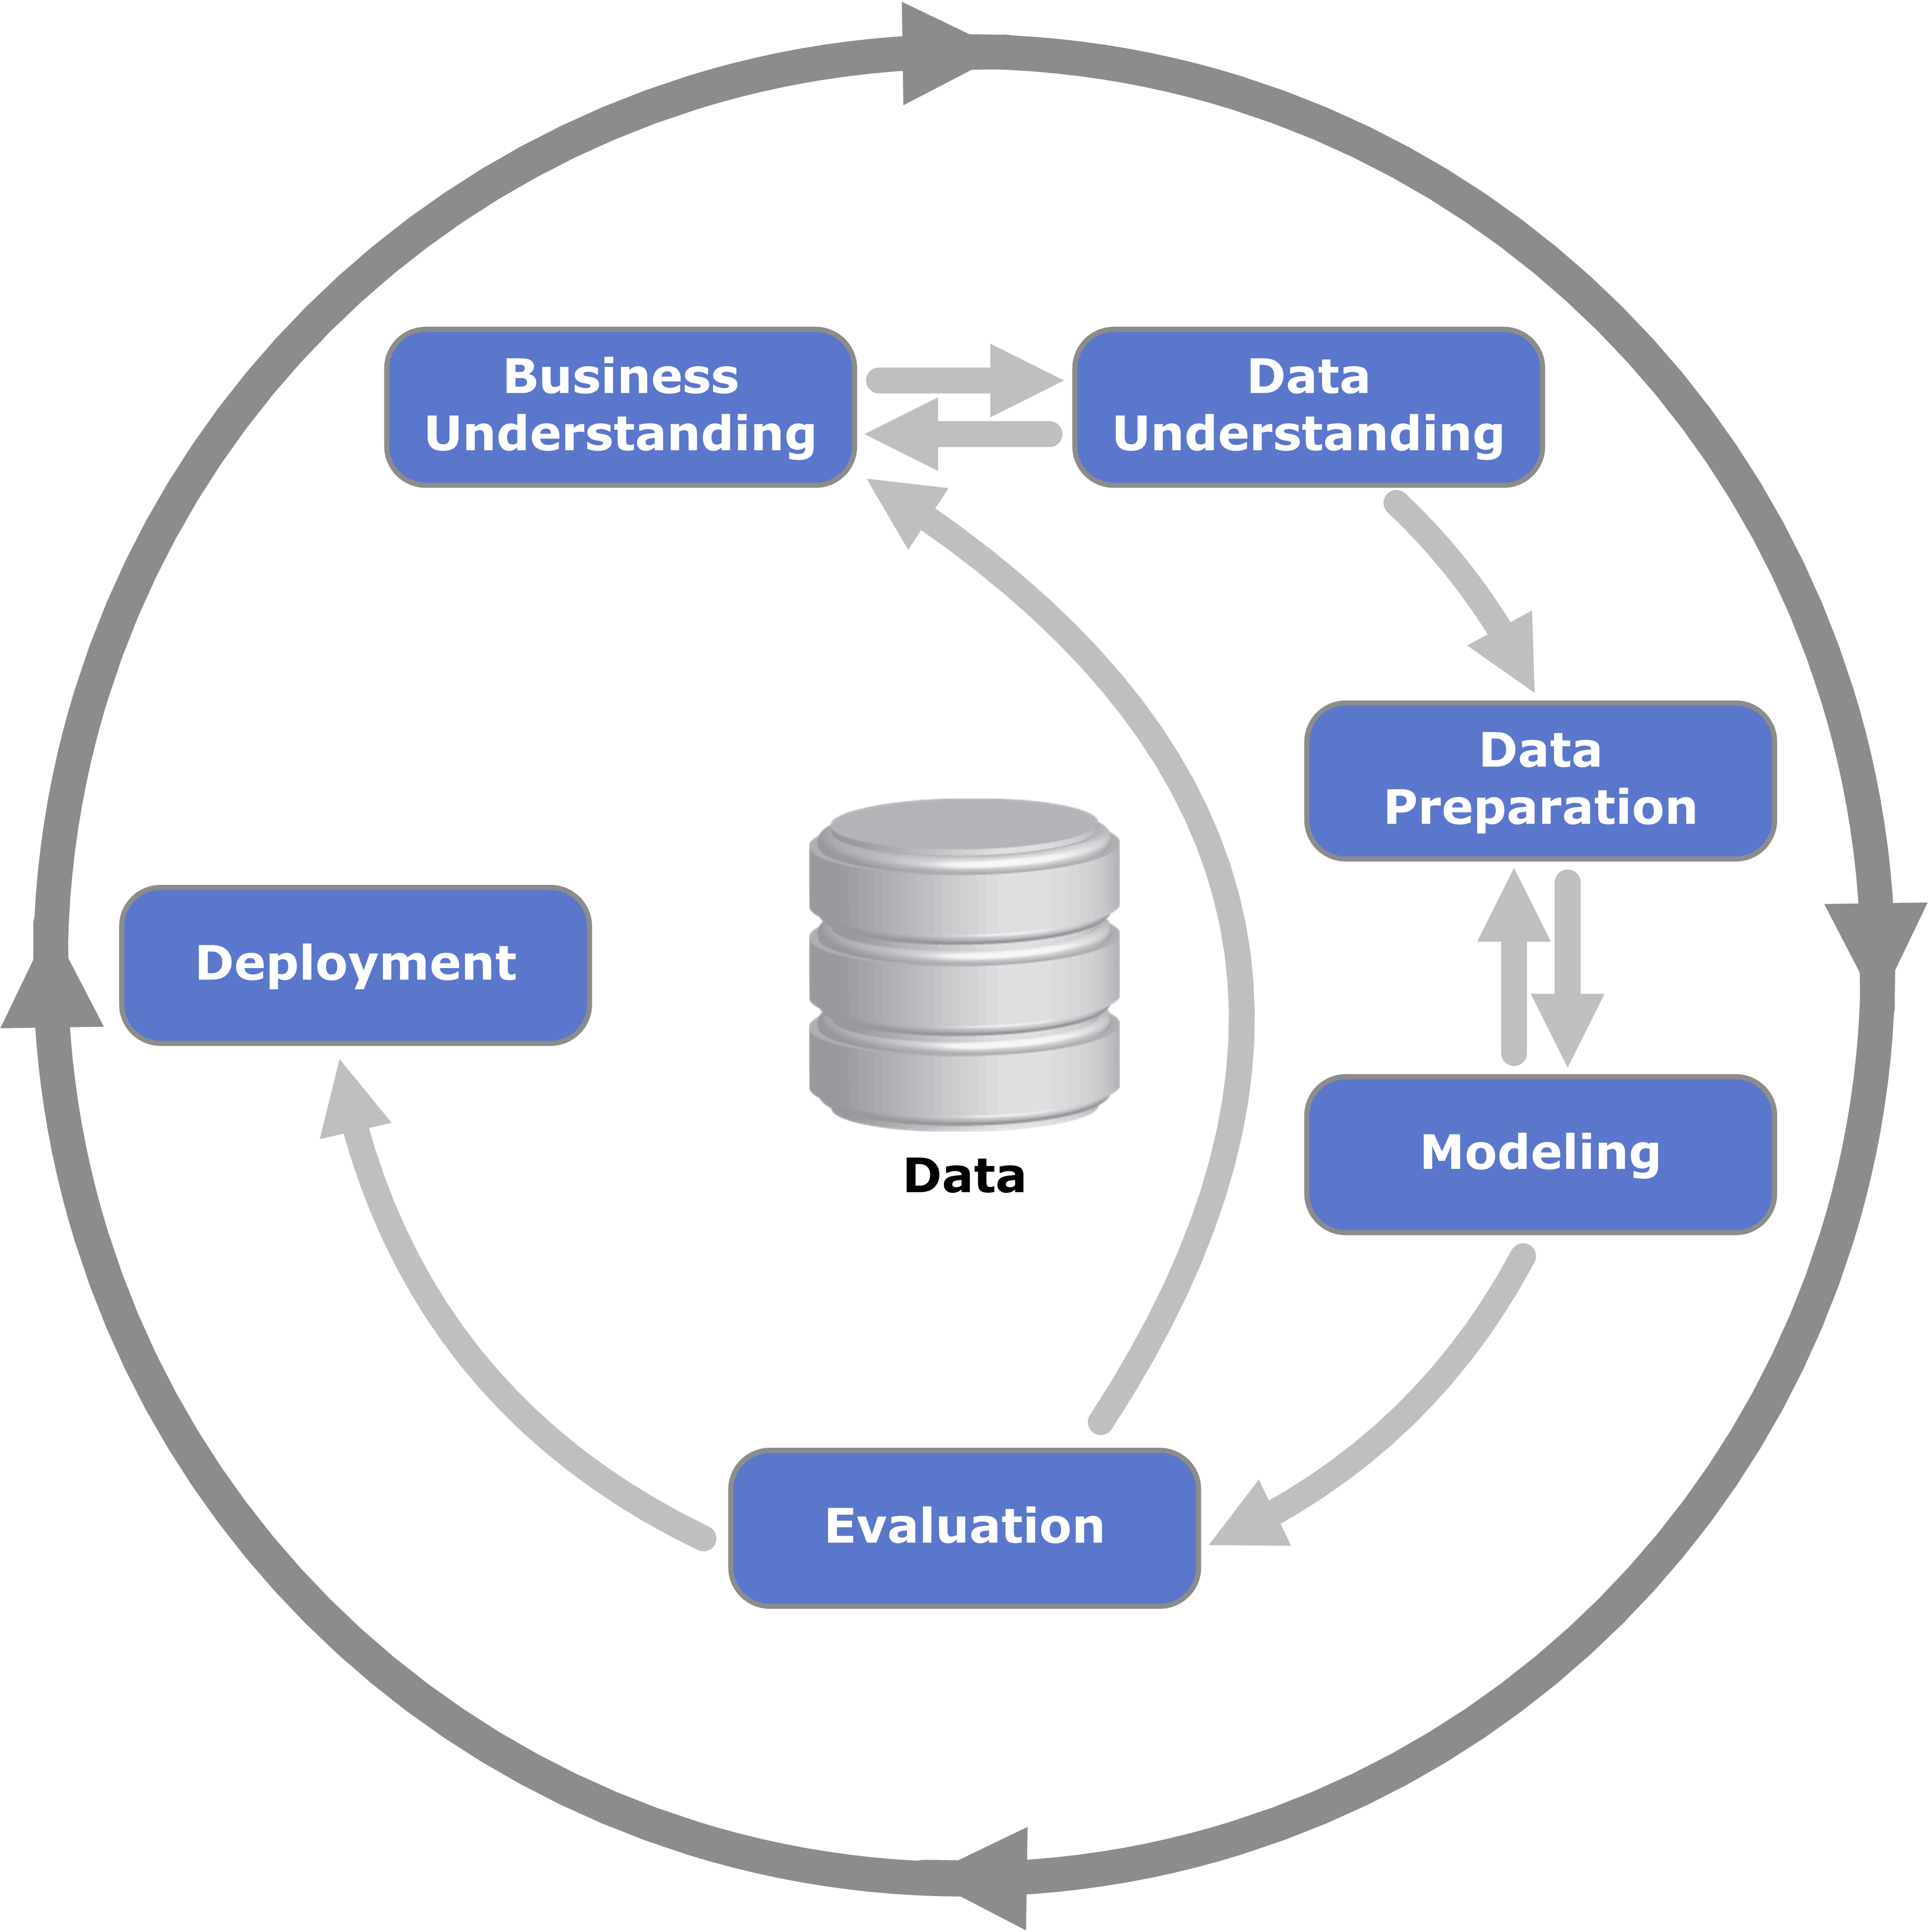

## Índice

- [1. Business Understanding](#s1)
    - [1.1 Problema y solución tecnológica](#s1-1)
    - [1.2 Objetivo](#s1-2)
    - [1.3 Dataset y definición de las clases](#s1-3)
- [2. Configuración inicial](#s2)
    - [2.1 Importación de librerías y variables de entorno](#s2-1)
    - [2.2 Configuración de GPU (CUDA)](#s2-2)
- [3. Data Understanding / EDA](#s3)
    - [3.1 Carga de datos y calidad estructural](#s3-1)
    - [3.2 Distribución de clases](#s3-2)
    - [3.3 Correlaciones](#s3-3)
    - [3.4 Hallazgos del EDA](#s3-4)
- [4. Data Preparation](#s4)
    - [4.1 Pipeline A: robustez al ruido (todas las variables)](#s4-1)
        - [4.1.1 Separación de variables y estandarización](#s4-1-1)
        - [4.1.2 Motor de ruido (Noise Engine) y niveles de SNR](#s4-1-2)
        - [4.1.3 Generación de los datasets ruidosos](#s4-1-3)
        - [4.1.4 Validación visual del efecto del ruido](#s4-1-4)
        - [4.1.5 Interpretación del efecto del ruido](#s4-1-5)
    - [4.2 Pipeline B: selección de características (ReliefF → 18 variables)](#s4-2)
        - [4.2.1 Variables, grupos (sujetos) y undersampling](#s4-2-1)
        - [4.2.2 Estandarización y ReliefF](#s4-2-2)
        - [4.2.3 Método del codo y selección de las 18 variables](#s4-2-3)
        - [4.2.4 Interpretación de la selección de características](#s4-2-4)
- [5. Modeling](#s5)
    - [5.1 Random Forest con ruido (todas las variables)](#s5-1)
        - [5.1.1 Interpretación de la robustez al ruido](#s5-1-1)
    - [5.2 Random Forest optimizado (18 variables, StratifiedGroupKFold)](#s5-2)
        - [5.2.1 Validación cruzada por grupos y grilla de hiperparámetros](#s5-2-1)
        - [5.2.2 Búsqueda de hiperparámetros (GridSearchCV)](#s5-2-2)
        - [5.2.3 Reporte de clasificación del mejor modelo](#s5-2-3)
        - [5.2.4 Interpretación del Random Forest optimizado](#s5-2-4)
    - [5.3 TabICL (v1) - Reducción de variables a 18](#s5-3)
        - [5.3.1 Interpretación de TabICL (v1)](#s5-3-1)
    - [5.4 TabICL (v2)](#s5-4)
    - [5.5 Mitra](#s5-5)
    - [5.6 Preparación de matrices NumPy para los modelos en GPU](#s5-6)
    - [5.7 TabDPT](#s5-7)
    - [5.8 TabPFN](#s5-8)
    - [5.9 TabFM](#s5-9)
    - [5.10 iLTM](#s5-10)
    - [5.11 EXAONE-Tabular](#s5-11)
- [6. Evaluation](#s6)
    - [6.1 Comparativa de modelos](#s6-1)
        - [6.1.1 Métricas globales y gráfico comparativo](#s6-1-1)
        - [6.1.2 Matrices de confusión](#s6-1-2)
    - [6.2 Exportación de resultados](#s6-2)
    - [6.3 Interpretación de resultados](#s6-3)
- [7. Deployment](#s7)
    - [7.1 Artefactos generados](#s7-1)
    - [7.2 Conclusiones](#s7-2)

## 1. Business Understanding <a id="s1"></a>

### 1.1 Problema y solución tecnológica <a id="s1-1"></a>

**Problema:** los trastornos de ansiedad son problemas de salud mental globales, pero los métodos tradicionales de detección (como los cuestionarios de autoreporte) tienen limitaciones: no son dinámicos ni cuantitativos.

**La solución tecnológica:** el uso de tecnología wearable permite el monitoreo en tiempo real de la respuesta del sistema nervioso autónomo mediante señales como la actividad electrodérmica (EDA), el volumen de pulso sanguíneo (BVP) y la electrocardiografía (ECG).

### 1.2 Objetivo <a id="s1-2"></a>

**Objetivo general:** evaluar el desempeño de los Modelos Fundacionales Tabulares basados en Transformers (inferencia *zero-shot* / *in-context learning*) para clasificar estados fisiológicos a partir de señales multimodales de wearables, contrastándolos con un modelo base robusto (Random Forest optimizado), y cuantificar la degradación del modelo base al inyectar niveles controlados de ruido gaussiano sintético en el dataset WESAD preprocesado (`may14_feats4.csv`).

**Objetivos específicos:**

1. Cuantificar la resiliencia al ruido gaussiano del Random Forest (118 variables) con distintos niveles de relación señal-ruido (SNR = 0.6, 0.4, 0.15, 0.1 y 0.01) frente al caso sin ruido (*Baseline*) — sección 5.1.
2. Reducir la dimensionalidad con ReliefF (de 118 a 18 variables) y optimizar el Random Forest con `GridSearchCV` bajo `StratifiedGroupKFold` (validación por sujeto) — secciones 4.2 y 5.2.
3. Evaluar ocho Modelos Fundacionales Tabulares (TabICL v1, TabICL v2, Mitra, TabDPT, TabPFN, TabFM, iLTM y EXAONE-Tabular) bajo el mismo esquema de validación por sujeto — secciones 5.3 a 5.11.
4. Comparar todos los modelos con Accuracy, F1-Score ponderado, ROC-AUC (One-vs-Rest), matrices de confusión y métricas por clase — sección 6.

**Alcance:** aunque el estudio parte del análisis de ruido gaussiano, su mayor énfasis está en el uso de Transformers tabulares. El análisis de ruido se aplicó al Random Forest (118 variables, `StratifiedKFold`), mientras que la comparación entre modelos fundacionales se realizó con datos sin ruido (18 variables, `StratifiedGroupKFold` sobre 270 muestras balanceadas). La evaluación de los Transformers bajo ruido queda como trabajo futuro (sección 7.3).

El análisis se desarrolló con librerías estándar de Python (scikit-learn) y se escaló a frameworks de Deep Learning (PyTorch, en GPU), con el fin de determinar qué paradigma algorítmico mantiene mejor su capacidad discriminativa y orientar el desarrollo de sistemas wearables de detección de estrés y ansiedad viables en el mundo real.

### 1.3 Dataset y definición de las clases <a id="s1-3"></a>

El dataset es una versión preprocesada de **WESAD** (`may14_feats4.csv`): 577 instancias con 118 variables predictoras (prefijos `EDA_`, `ECG_`, `Resp_`, `TEMP_`, `ACC_` y `net_acc_`), la etiqueta `label` y el identificador de sujeto `subject`. La etiqueta tiene tres clases:

| Clase | Estado | Descripción |
|---|---|---|
| **0** | Reposo / neutral (línea base) | Al inicio del protocolo, los sujetos pasaban un periodo prolongado (aproximadamente 20 minutos) realizando actividades tranquilas, como leer revistas, para establecer una línea base fisiológica sin alteración emocional. |
| **1** | Emoción positiva inducida | Los participantes veían una selección de videoclips graciosos y neutrales, diseñados para provocar emociones positivas o de alegría. |
| **2** | Estrés psicosocial (alta activación simpática) | Estado inducido mediante pruebas estandarizadas de laboratorio como el Trier Social Stress Test (TSST), que combina tareas de hablar en público y aritmética mental bajo presión. |

> **Nota:** en este cuaderno el problema se trata como **clasificación multiclase de 3 clases**, por lo que la clase 1 se mantiene como una categoría distinta. En la tarea binaria final (ansioso vs. no ansioso), esta clase suele agruparse con la línea base (clase 0) bajo la categoría "no ansioso / no estresado"; esa variante no se evalúa aquí.

## 2. Configuración inicial <a id="s2"></a>

### 2.1 Importación de librerías y variables de entorno <a id="s2-1"></a>

Las variables de entorno para GPU deben definirse **antes** de importar `torch`, `tabicl` o `tabdpt`. Luego se importan las librerías de manipulación de datos, preprocesamiento, validación cruzada, métricas y los modelos tabulares (Mitra usa la interfaz sklearn de AutoGluon cuando está disponible).

In [2]:
# --- Variables de entorno para GPU (deben ir ANTES de importar torch / tabicl / tabdpt) ---
import os
os.environ["TORCH_COMPILE_DISABLE"] = "1"   # evita bloqueos de Triton/inductor en Windows
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # evita choques de OpenMP (libiomp vs libomp) entre torch/sklearn/faiss/autogluon en Windows

# Manipulación de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y selección de características
from sklearn.preprocessing import StandardScaler, label_binarize
from imblearn.under_sampling import RandomUnderSampler
from skrebate import ReliefF

# Modelos y validación cruzada
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (StratifiedKFold, StratifiedGroupKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)

# Métricas
from sklearn.metrics import (roc_curve, auc, classification_report,
                             roc_auc_score, accuracy_score, f1_score)

# Transformer tabular
import time
from tabicl import TabICLClassifier
from tabdpt import TabDPTClassifier

# Mitra (AutoGluon): interfaz sklearn si está disponible; de lo contrario se usa TabularPredictor
try:
    from autogluon.tabular.models.mitra.sklearn_interface import MitraClassifier
    usar_sklearn_mitra = True
except ImportError:
    from autogluon.tabular import TabularPredictor
    usar_sklearn_mitra = False

# Exportar métricas
import os

pd.reset_option('display.max_rows'); pd.reset_option('display.max_columns')

### 2.2 Configuración de GPU (CUDA) <a id="s2-2"></a>

Detecta la RTX 5060, define `DEVICE` y deja funciones auxiliares para pasar el dispositivo a cada modelo.
La RTX 5060 es arquitectura Blackwell (sm_120): requiere **PyTorch compilado con CUDA 12.8 o superior** (`cu128`).

In [3]:
import gc
import inspect
import torch

# Si es True usa solo el kernel de atención "math" (lo más estable en Windows + Blackwell).
# Si todo corre bien, ponlo en False para que PyTorch use FlashAttention / mem-efficient (más rápido).
SDPA_SEGURO = True

print(f"PyTorch {torch.__version__} | compilado con CUDA: {torch.version.cuda}")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# bf16 autocast envolviendo fit/predict de los modelos tabulares puede provocar cierres nativos del kernel
# (0xC0000005) y no es necesario: estos modelos manejan su propia precisión. Déjalo en False.
USE_AUTOCAST = False

if DEVICE == "cuda":
    cap = torch.cuda.get_device_capability(0)
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {torch.cuda.get_device_name(0)} | sm_{cap[0]}{cap[1]} | VRAM: {props.total_memory/1024**3:.1f} GB")

    if not any(a.endswith(f"{cap[0]}{cap[1]}") for a in torch.cuda.get_arch_list()):
        print("⚠️ Esta build de PyTorch NO incluye kernels para tu GPU. Reinstala con CUDA 12.8+:\n"
              "   pip install --upgrade torch torchvision --index-url https://download.pytorch.org/whl/cu128")

    # Aceleración de matmul en Ampere/Blackwell
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")

    if SDPA_SEGURO:
        torch.backends.cuda.enable_flash_sdp(False)
        torch.backends.cuda.enable_mem_efficient_sdp(False)
        torch.backends.cuda.enable_math_sdp(True)
    torch._dynamo.config.suppress_errors = True
else:
    print("⚠️ CUDA no disponible: se usará CPU. Instala PyTorch con soporte CUDA 12.8+:\n"
          "   pip install --upgrade torch torchvision --index-url https://download.pytorch.org/whl/cu128\n"
          "   (y reinicia el kernel)")

print(f"Dispositivo activo para los modelos: {DEVICE.upper()}")


def kw_gpu(cls, **kwargs):
    """Devuelve solo los kwargs que el constructor de `cls` realmente acepta (evita errores por
    diferencias de versión entre librerías) e informa cuáles se aplicaron."""
    validos = set(inspect.signature(cls.__init__).parameters)
    aplicados = {k: v for k, v in kwargs.items() if k in validos}
    print(f"{cls.__name__}: parámetros GPU aplicados -> {aplicados}")
    return aplicados


def liberar_gpu():
    """Libera memoria de la GPU entre modelos/folds."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


PyTorch 2.11.0+cu128 | compilado con CUDA: 12.8
GPU: NVIDIA GeForce RTX 5060 Laptop GPU | sm_120 | VRAM: 7.9 GB
Dispositivo activo para los modelos: CUDA


## 3. Data Understanding / EDA <a id="s3"></a>

### 3.1 Carga de datos y calidad estructural <a id="s3-1"></a>

In [4]:
#Carga de data
df = pd.read_csv("../anxietyFB-main/data/may14_feats4.csv")
df

,Unnamed: 0,net_acc_C_mean,net_acc_C_std,net_acc_C_min,net_acc_C_max,net_acc_mean,net_acc_std,net_acc_min,net_acc_max,EDA_mean,...,Resp_C_Inhal_std,Resp_C_Exhal_mean,Resp_C_Exhal_std,Resp_C_I/E,TEMP_drange,TEMP_C_drange,TEMP_slope,TEMP_C_slope,subject,label
0,0,0.000531,0.000086,0.000371,0.000788,0.025961,0.013811,0.000000,0.087383,1.303625,...,0.622539,1.839898,0.741267,1.113083,1.003357,1.014887,-0.000253,-1.377799e-06,2,1
1,1,0.000426,0.000004,0.000400,0.000443,0.027640,0.010597,0.002752,0.054356,0.892549,...,0.189863,1.487778,0.439986,1.003521,1.002524,1.016588,-0.000161,-6.099829e-06,2,1
2,2,0.000427,0.000004,0.000407,0.000444,0.028389,0.006937,0.000000,0.066053,0.598712,...,0.345404,1.431053,0.437193,0.927337,1.003640,1.010799,0.000535,1.041127e-06,2,1
3,3,0.000460,0.000050,0.000397,0.000643,0.033268,0.007670,0.000000,0.074998,0.504760,...,0.252339,1.567381,0.678817,0.942731,1.003355,1.015345,-0.000256,-3.158520e-06,2,1
4,4,0.000441,0.000003,0.000427,0.000458,0.037021,0.001284,0.027522,0.043347,0.456286,...,0.138846,1.338357,0.116270,1.007579,1.001957,1.015297,0.000260,-4.752758e-06,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,572,0.000608,0.000018,0.000519,0.000721,0.029596,0.007250,0.002064,0.070870,1.019429,...,0.925958,2.198571,0.806926,0.969352,1.003035,1.009289,-0.000225,-1.991283e-06,17,0
573,573,0.000608,0.000004,0.000593,0.000625,0.030401,0.000552,0.028898,0.031650,1.015634,...,0.449312,1.729810,0.163246,0.999835,1.002431,1.007332,-0.000249,2.515800e-07,17,0
574,574,0.000607,0.000006,0.000536,0.000678,0.029762,0.000721,0.026834,0.035779,1.012849,...,0.561151,1.982527,0.814294,1.034089,1.002741,1.006967,-0.000174,-2.817866e-07,17,0
575,575,0.000603,0.000009,0.000512,0.000682,0.033337,0.001668,0.028898,0.041283,1.005232,...,0.203108,1.604202,0.174612,0.931954,1.001217,1.007922,0.000068,-1.085821e-06,17,0


In [5]:
df = df.drop(columns=["Unnamed: 0"])
df

,net_acc_C_mean,net_acc_C_std,net_acc_C_min,net_acc_C_max,net_acc_mean,net_acc_std,net_acc_min,net_acc_max,EDA_mean,EDA_std,...,Resp_C_Inhal_std,Resp_C_Exhal_mean,Resp_C_Exhal_std,Resp_C_I/E,TEMP_drange,TEMP_C_drange,TEMP_slope,TEMP_C_slope,subject,label
0,0.000531,0.000086,0.000371,0.000788,0.025961,0.013811,0.000000,0.087383,1.303625,0.151736,...,0.622539,1.839898,0.741267,1.113083,1.003357,1.014887,-0.000253,-1.377799e-06,2,1
1,0.000426,0.000004,0.000400,0.000443,0.027640,0.010597,0.002752,0.054356,0.892549,0.142093,...,0.189863,1.487778,0.439986,1.003521,1.002524,1.016588,-0.000161,-6.099829e-06,2,1
2,0.000427,0.000004,0.000407,0.000444,0.028389,0.006937,0.000000,0.066053,0.598712,0.066870,...,0.345404,1.431053,0.437193,0.927337,1.003640,1.010799,0.000535,1.041127e-06,2,1
3,0.000460,0.000050,0.000397,0.000643,0.033268,0.007670,0.000000,0.074998,0.504760,0.018053,...,0.252339,1.567381,0.678817,0.942731,1.003355,1.015345,-0.000256,-3.158520e-06,2,1
4,0.000441,0.000003,0.000427,0.000458,0.037021,0.001284,0.027522,0.043347,0.456286,0.036839,...,0.138846,1.338357,0.116270,1.007579,1.001957,1.015297,0.000260,-4.752758e-06,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,0.000608,0.000018,0.000519,0.000721,0.029596,0.007250,0.002064,0.070870,1.019429,0.007279,...,0.925958,2.198571,0.806926,0.969352,1.003035,1.009289,-0.000225,-1.991283e-06,17,0
573,0.000608,0.000004,0.000593,0.000625,0.030401,0.000552,0.028898,0.031650,1.015634,0.001740,...,0.449312,1.729810,0.163246,0.999835,1.002431,1.007332,-0.000249,2.515800e-07,17,0
574,0.000607,0.000006,0.000536,0.000678,0.029762,0.000721,0.026834,0.035779,1.012849,0.002051,...,0.561151,1.982527,0.814294,1.034089,1.002741,1.006967,-0.000174,-2.817866e-07,17,0
575,0.000603,0.000009,0.000512,0.000682,0.033337,0.001668,0.028898,0.041283,1.005232,0.003284,...,0.203108,1.604202,0.174612,0.931954,1.001217,1.007922,0.000068,-1.085821e-06,17,0


In [6]:
df.shape

(577, 120)

In [7]:
df.isnull().sum()

net_acc_C_mean    0
net_acc_C_std     0
net_acc_C_min     0
net_acc_C_max     0
net_acc_mean      0
                 ..
TEMP_C_drange     0
TEMP_slope        0
TEMP_C_slope      0
subject           0
label             0
Length: 120, dtype: int64

In [8]:
df.isnull().sum().sum() #Al no poder ver todas las columnas

np.int64(0)

### 3.2 Distribución de clases <a id="s3-2"></a>

Clases: **0** = reposo/neutral, **1** = emoción positiva inducida, **2** = estrés psicosocial (ver sección 1.3).

In [9]:
df['label'].value_counts(normalize=True) * 100

label
1    54.072790
2    30.329289
0    15.597920
Name: proportion, dtype: float64

C:\Users\estef\AppData\Local\Temp\ipykernel_23104\2510921168.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='label', palette='viridis')


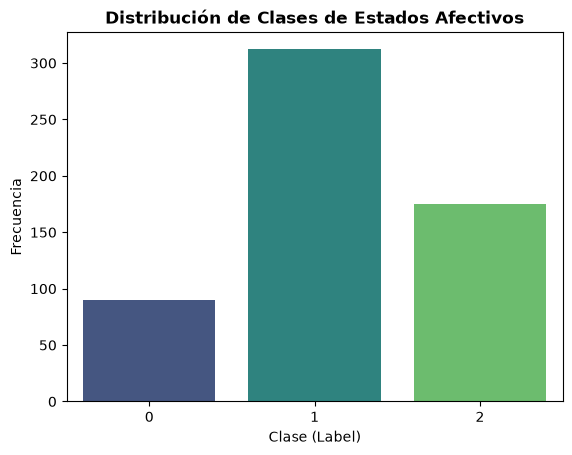

In [10]:
# Visualización del Desbalanceo de Clases
plt.figure()
ax = sns.countplot(data=df, x='label', palette='viridis')
plt.title("Distribución de Clases de Estados Afectivos", fontweight='bold')
plt.xlabel("Clase (Label)")
plt.ylabel("Frecuencia")
plt.show()

### 3.3 Correlaciones <a id="s3-3"></a>

In [11]:
correlations = df.corr()
correlations["label"].sort_values(ascending=False)


label           1.000000
EDA_SCL_max     0.647831
EDA_SCL_mean    0.641174
EDA_SCL_min     0.629194
ECG_bpm         0.548184
                  ...   
ECG_min        -0.304055
ECG_pnn20      -0.321408
EDA_SCR_min    -0.425529
Resp_C_rate    -0.526967
ECG_ibi        -0.529081
Name: label, Length: 120, dtype: float64

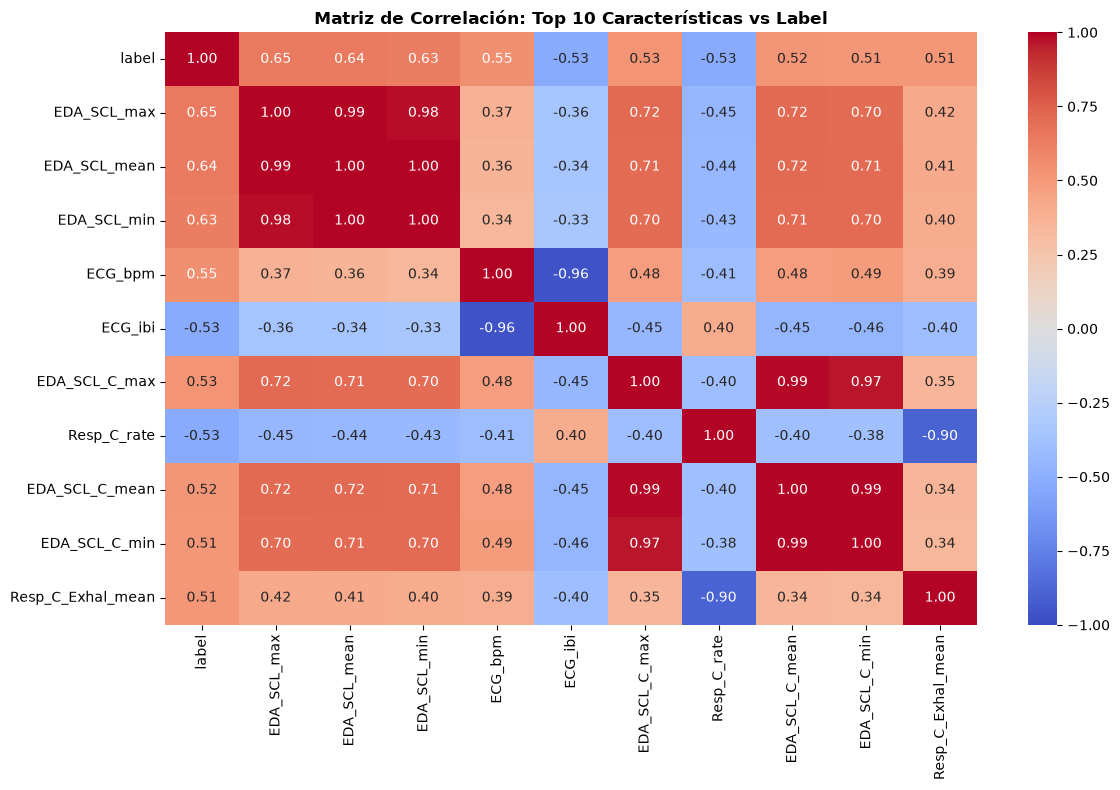

In [12]:
top_10_corr_vars = df.corr()['label'].abs().sort_values(ascending=False).head(11).index
df_top_10 = df[top_10_corr_vars]

plt.figure(figsize=(12, 8))
sns.heatmap(df_top_10.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlación: Top 10 Características vs Label", fontweight='bold')
plt.tight_layout()
plt.show()

### 3.4 Hallazgos del EDA <a id="s3-4"></a>

**Calidad Estructural e Integridad**: El conjunto de datos presenta una integridad del 100%. Tras eliminar el índice residual (Unnamed: 0), la matriz de datos consta de 577 instancias y 120 columnas: 118 variables predictoras, la etiqueta (label) y el identificador de sujeto (subject). La validación de valores nulos (df.isnull().sum().sum()) confirmó la ausencia total de datos faltantes, lo que exime al proyecto de aplicar técnicas de imputación complejas y garantiza que las métricas extraídas de los sensores son continuas y completas.

**Desbalanceo de Clases**: El análisis de la distribución porcentual de la variable objetivo (label) y su respectivo gráfico de conteo revelan un desbalanceo entre los tres estados: la clase 1 (emoción positiva) concentra el 54.1 % de las instancias, la clase 2 (estrés) el 30.3 % y la clase 0 (reposo) el 15.6 %. Este hallazgo empírico justifica plenamente la decisión metodológica de utilizar métricas de evaluación robustas para clases desbalanceadas, tales como el F1-Score, Curva ROC y AUC, y la necesidad de aplicar validación cruzada estratificada (StratifiedKFold en la sección 5.1 y StratifiedGroupKFold, por sujeto, a partir de la sección 5.2).

**Poder Predictivo y Multicolinealidad**: La extracción de las correlaciones absolutas contra la variable label y su posterior visualización en el mapa de calor (Top 10) validan lo establecido en la revisión de la literatura. Biomarcadores específicos del sistema nervioso autónomo (como la actividad electrodérmica máxima y métricas cardíacas) presentan la mayor correlación con la etiqueta del estado (clases 0, 1 y 2). Asimismo, el mapa de calor revela la presencia de multicolinealidad entre algunas características derivadas de la misma señal, lo que sugiere que algoritmos de ensamble como Random Forest serán ideales por su capacidad intrínseca para manejar variables correlacionadas sin necesidad de eliminarlas manualmente.

## 4. Data Preparation <a id="s4"></a>

### 4.1 Pipeline A: robustez al ruido (todas las variables) <a id="s4-1"></a>

Estandarización de las variables, construcción del *Noise Engine* y generación de los datasets contaminados con distintos niveles de SNR.

#### 4.1.1 Separación de variables y estandarización <a id="s4-1-1"></a>

In [13]:
#Separar variable objetivo de las caracteristicas
X = df.drop(columns=["label", "subject"])
y = df["label"]

In [14]:
#Estandarizamos las variables con Standart Scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-0.25814057,  5.28062755, -1.45955378, ...,  0.13080757,
        -0.43525933, -0.3316155 ],
       [-1.43778578, -0.47704779, -1.13249042, ...,  0.16642096,
        -0.26613935, -0.99707857],
       [-1.4287397 , -0.49531386, -1.04955118, ...,  0.04522491,
         1.0097774 ,  0.00927732],
       ...,
       [ 0.60511717, -0.34271062,  0.41832108, ..., -0.03498634,
        -0.28956599, -0.1771574 ],
       [ 0.55736832, -0.16100534,  0.14289944, ..., -0.01499737,
         0.15305494, -0.29046784],
       [ 0.59296951, -0.51207621,  0.95351465, ..., -0.04729078,
        -0.97720921, -0.14511061]], shape=(577, 118))

In [15]:
#Se transforma a dataframe
X_scaled_df = pd.DataFrame(X_scaled, columns= X.columns)
X_scaled_df

,net_acc_C_mean,net_acc_C_std,net_acc_C_min,net_acc_C_max,net_acc_mean,net_acc_std,net_acc_min,net_acc_max,EDA_mean,EDA_std,...,Resp_C_rate,Resp_C_Inhal_mean,Resp_C_Inhal_std,Resp_C_Exhal_mean,Resp_C_Exhal_std,Resp_C_I/E,TEMP_drange,TEMP_C_drange,TEMP_slope,TEMP_C_slope
0,-0.258141,5.280628,-1.459554,0.816056,-0.388016,2.553181,-1.067277,1.996634,-0.250790,0.911556,...,0.247000,-0.477309,0.054507,-0.552747,0.604169,0.475343,-0.061238,0.130808,-0.435259,-0.331616
1,-1.437786,-0.477048,-1.132490,-0.921396,-0.206106,1.675475,-0.850440,0.195723,-0.404933,0.815679,...,1.516810,-1.577720,-0.980722,-1.492152,-0.202862,-0.332646,-0.401218,0.166421,-0.266139,-0.997079
2,-1.428740,-0.495314,-1.049551,-0.915156,-0.124924,0.676310,-1.067277,0.833546,-0.515114,0.067814,...,1.225702,-1.607926,-0.608571,-1.643486,-0.210345,-0.894480,0.054616,0.045225,1.009777,0.009277
3,-1.056573,2.769038,-1.162224,0.086686,0.403776,0.876386,-1.067277,1.321293,-0.550344,-0.417524,...,1.267935,-1.610017,-0.831241,-1.279782,0.436885,-0.780950,-0.062004,0.140393,-0.440556,-0.582568
4,-1.271272,-0.561905,-0.824206,-0.849292,0.810384,-0.866957,1.101100,-0.404581,-0.568520,-0.230756,...,2.550108,-1.723712,-1.102785,-1.890784,-1.069991,-0.302721,-0.632641,0.139382,0.505718,-0.807239
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,0.618659,0.485390,0.227404,0.479103,0.005884,0.761792,-0.904649,1.096179,-0.357356,-0.524644,...,-0.748013,0.438252,0.780475,0.404141,0.780046,-0.584627,-0.192584,0.013626,-0.384049,-0.418072
573,0.614749,-0.506421,1.061493,-0.006218,0.093090,-1.067061,1.209519,-1.042404,-0.358779,-0.579712,...,0.741798,-0.606543,-0.359958,-0.846446,-0.944157,-0.359828,-0.439169,-0.027350,-0.428211,-0.101991
574,0.605117,-0.342711,0.418321,0.259322,0.023795,-1.020707,1.046890,-0.817290,-0.359823,-0.576622,...,0.708506,-0.494480,-0.092369,-0.172232,0.799782,-0.107214,-0.312744,-0.034986,-0.289566,-0.177157
575,0.557368,-0.161005,0.142899,0.282202,0.411213,-0.762112,1.209519,-0.517138,-0.362680,-0.564358,...,1.471385,-1.192358,-0.949032,-1.181550,-0.913712,-0.860430,-0.934746,-0.014997,0.153055,-0.290468


#### 4.1.2 Motor de ruido (Noise Engine) y niveles de SNR <a id="s4-1-2"></a>

In [16]:
# Construcción del Motor de Ruido (Noise Engine)
def add_gaussian_noise(signal, snr):
    """
    Inyecta ruido gaussiano a una señal dada una Relación Señal-Ruido (SNR).
    Basado en la Ecuación (1) y (2) del documento de referencia:
    Potencia de la señal E(S^2) / SNR = Varianza del ruido (sigma^2).
    """
    # Calculamos la potencia de la señal: E(S^2)
    signal_power = np.mean(signal ** 2)
    
    # Calculamos la varianza del ruido según el SNR requerido
    # Si SNR es muy bajo (ej. 0.01), el ruido será enorme.
    noise_variance = signal_power / snr
    
    # Generamos el ruido gaussiano N(0, sigma^2)
    noise = np.random.normal(loc=0.0, scale=np.sqrt(noise_variance), size=signal.shape)
    
    # Retornamos la señal contaminada con ruido
    return signal + noise

def generate_noisy_datasets(X_df, snr_levels):
    """
    Genera un diccionario con múltiples DataFrames, cada uno contaminado
    con un nivel específico de ruido SNR.
    """
    datasets = {}
    for snr in snr_levels:
        # Aplicamos la función de ruido columna por columna
        noisy_X = X_df.apply(lambda col: add_gaussian_noise(col, snr))
        datasets[snr] = noisy_X
        print(f"Dataset generado para SNR: {snr}")
        
    return datasets

In [17]:
# Definición de los Niveles SNR (Signal-to-Noise Ratios)
# Según el artículo, se evalúan niveles desde mucha interferencia (0.01) 
# hasta poca interferencia (0.6).
snr_list = [0.01, 0.1, 0.15, 0.4, 0.6]

#### 4.1.3 Generación de los datasets ruidosos <a id="s4-1-3"></a>

In [18]:
print("--- INICIANDO INYECCIÓN DE RUIDO SINTÉTICO ---")
# Generamos los datasets ruidosos basados en las características escaladas
noisy_X_dict = generate_noisy_datasets(X_scaled_df, snr_list)

# Agregamos el dataset base (sin ruido adicional) al diccionario para la validación inicial
noisy_X_dict['Baseline'] = X_scaled_df
print(f"\nPreparación completada: {len(noisy_X_dict)} escenarios generados.")

--- INICIANDO INYECCIÓN DE RUIDO SINTÉTICO ---
Dataset generado para SNR: 0.01
Dataset generado para SNR: 0.1
Dataset generado para SNR: 0.15
Dataset generado para SNR: 0.4
Dataset generado para SNR: 0.6

Preparación completada: 6 escenarios generados.


#### 4.1.4 Validación visual del efecto del ruido <a id="s4-1-4"></a>

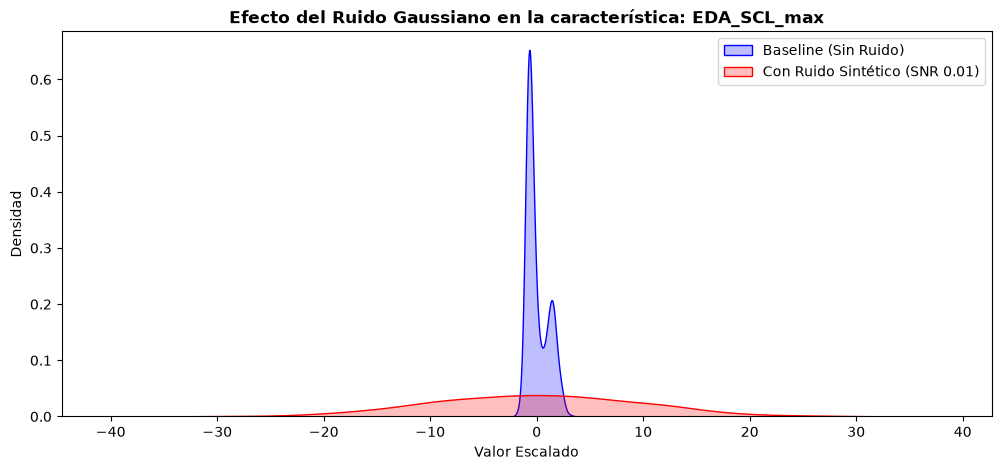

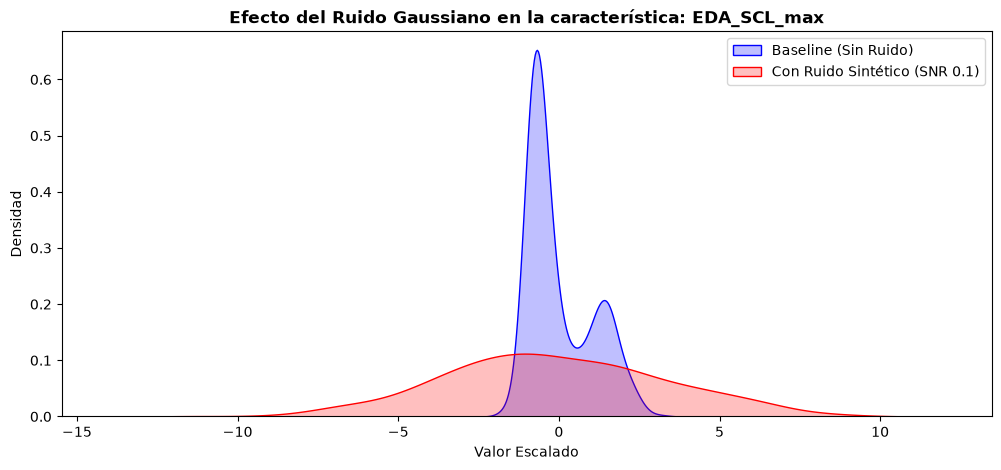

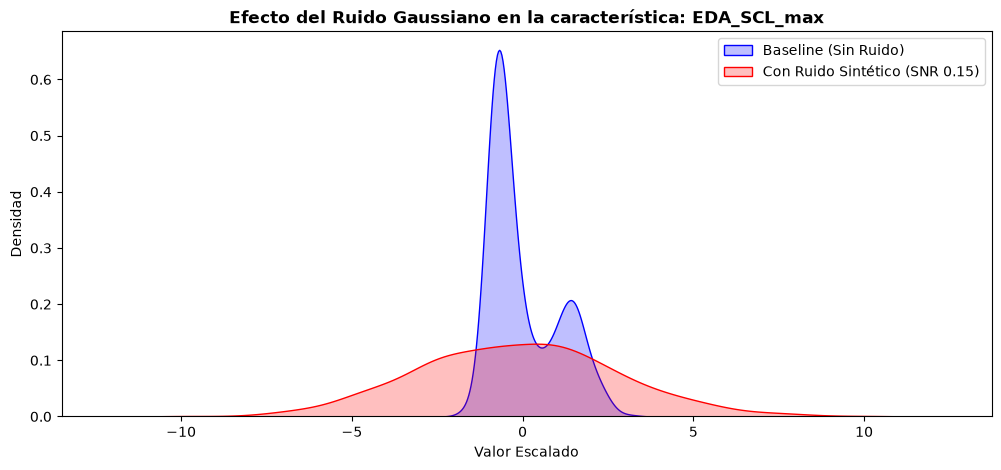

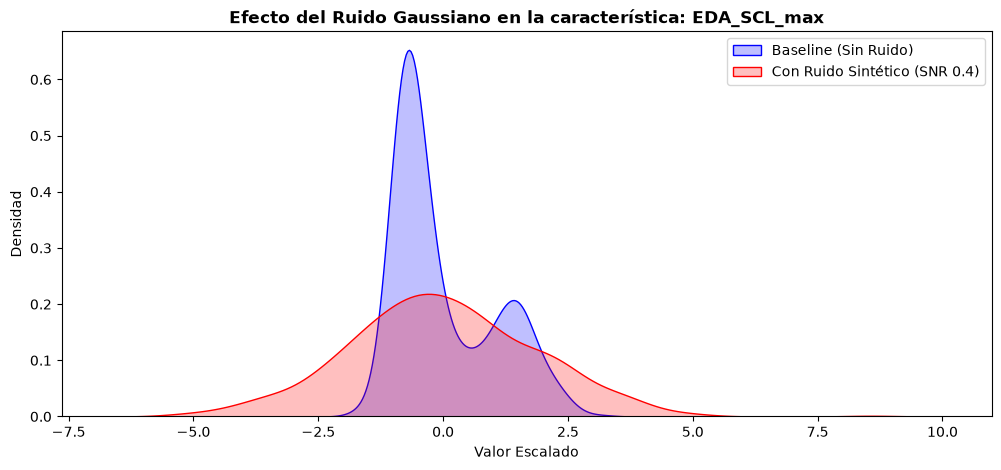

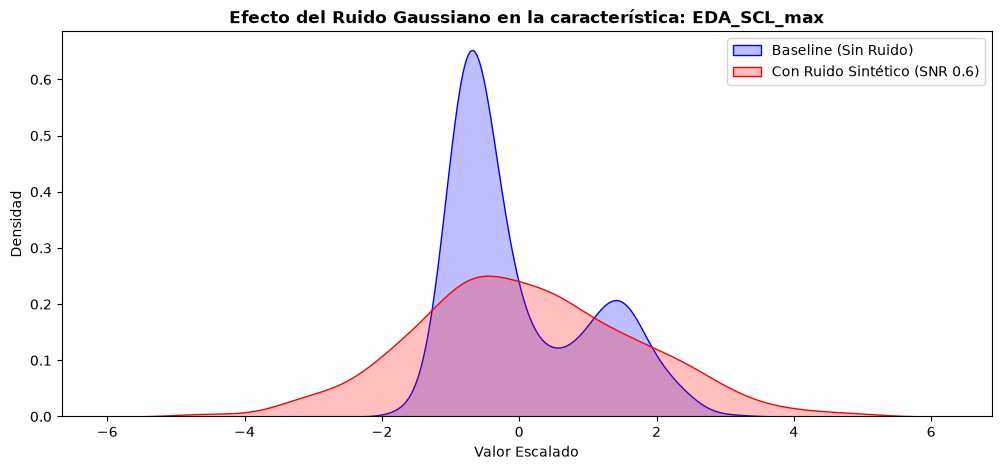

In [19]:
feature_to_plot = 'EDA_SCL_max'  # El biomarcador más importante

for snr in snr_list:
    plt.figure(figsize=(12, 5))
    sns.kdeplot(noisy_X_dict['Baseline'][feature_to_plot], label='Baseline (Sin Ruido)', fill=True, color='blue')
    sns.kdeplot(noisy_X_dict[snr][feature_to_plot], label=f'Con Ruido Sintético (SNR {snr})', fill=True, color='red')
    plt.title(f"Efecto del Ruido Gaussiano en la característica: {feature_to_plot}", fontweight='bold')
    plt.xlabel("Valor Escalado")
    plt.ylabel("Densidad")
    plt.legend()
    plt.show()

#### 4.1.5 Interpretación del efecto del ruido <a id="s4-1-5"></a>

**Validación Visual de la Degradación (El Efecto del Ruido)**: La gráfica del biomarcador principal (EDA_SCL_max) demuestra perfectamente el funcionamiento del Noise Engine. La distribución Baseline (azul) muestra la señal original estandarizada, fuertemente concentrada alrededor del cero y con picos definidos; esta es la estructura limpia de donde los algoritmos extraen patrones fácilmente. Por el contrario, la distribución con Ruido Extremo a SNR 0.01 (rojo) ilustra cómo una interferencia severa "aplasta" la información original, dispersando los datos en un rango masivo (de -40 a +20). Visual y matemáticamente, la varianza del ruido ha ahogado por completo la varianza biológica de la señal del paciente.

**Estandarización como Pilar Técnico**: La aplicación del StandardScaler fue un paso fundamental antes de inyectar el ruido. Garantizó que las perturbaciones gaussianas se aplicaran de manera equitativa basándose en la potencia real de cada señal, evitando que variables con escalas naturalmente grandes (como los milivoltios del ECG) dominaran artificialmente sobre variables de rangos pequeños (como las variaciones de temperatura).

**Simulación de la Incertidumbre Clínica**: Al generar sistemáticamente múltiples datasets con distintos niveles de Relación Señal-Ruido (desde una interferencia catastrófica de 0.01 hasta niveles más leves como 0.6), el proyecto ha dejado de ser un análisis de "laboratorio perfecto". Ahora se ha transformado en un entorno de prueba de estrés real para la Inteligencia Artificial.

### 4.2 Pipeline B: selección de características (ReliefF → 18 variables) <a id="s4-2"></a>

Balanceo por *undersampling*, estandarización, ranking de variables con ReliefF y selección de las 18 mejores por el método del codo.

#### 4.2.1 Variables, grupos (sujetos) y undersampling <a id="s4-2-1"></a>

In [20]:
X = df.drop(columns=['label', 'subject'])
y = df['label']
groups = df['subject'] # Necesario para StratifiedGroupKFold 


In [21]:
# Undersampling (Igualar clases)
# Añadimos 'subject' a X temporalmente para no perder a qué paciente pertenece cada fila tras el recorte
X_temp = X.copy()
X_temp['subject'] = groups

rus = RandomUnderSampler(random_state=42)
X_res, y_res = rus.fit_resample(X_temp, y)

In [22]:
# Separamos el 'subject' del dataset ya balanceado
groups_res = X_res['subject']
X_res = X_res.drop(columns=['subject'])

print("--- DISTRIBUCIÓN TRAS UNDERSAMPLING ---")
print(y_res.value_counts())

--- DISTRIBUCIÓN TRAS UNDERSAMPLING ---
label
0    90
1    90
2    90
Name: count, dtype: int64


#### 4.2.2 Estandarización y ReliefF <a id="s4-2-2"></a>

In [23]:
# Escalar los datos (ReliefF es sensible a las escalas)
scaler = StandardScaler()
X_res_scaled = scaler.fit_transform(X_res)

In [24]:
# Aplicar ReliefF
print("\nCalculando importancia con ReliefF (esto puede tardar unos segundos)...")
# Usamos n_neighbors=20 (estándar para datasets medianos)
fs = ReliefF(n_features_to_select=X_res_scaled.shape[1], n_neighbors=20, n_jobs=-1)
fs.fit(X_res_scaled, y_res.values)

relief_scores = pd.DataFrame({
    'Feature': X_res.columns,
    'Score': fs.feature_importances_
}).sort_values(by='Score', ascending=False)


Calculando importancia con ReliefF (esto puede tardar unos segundos)...


#### 4.2.3 Método del codo y selección de las 18 variables <a id="s4-2-3"></a>

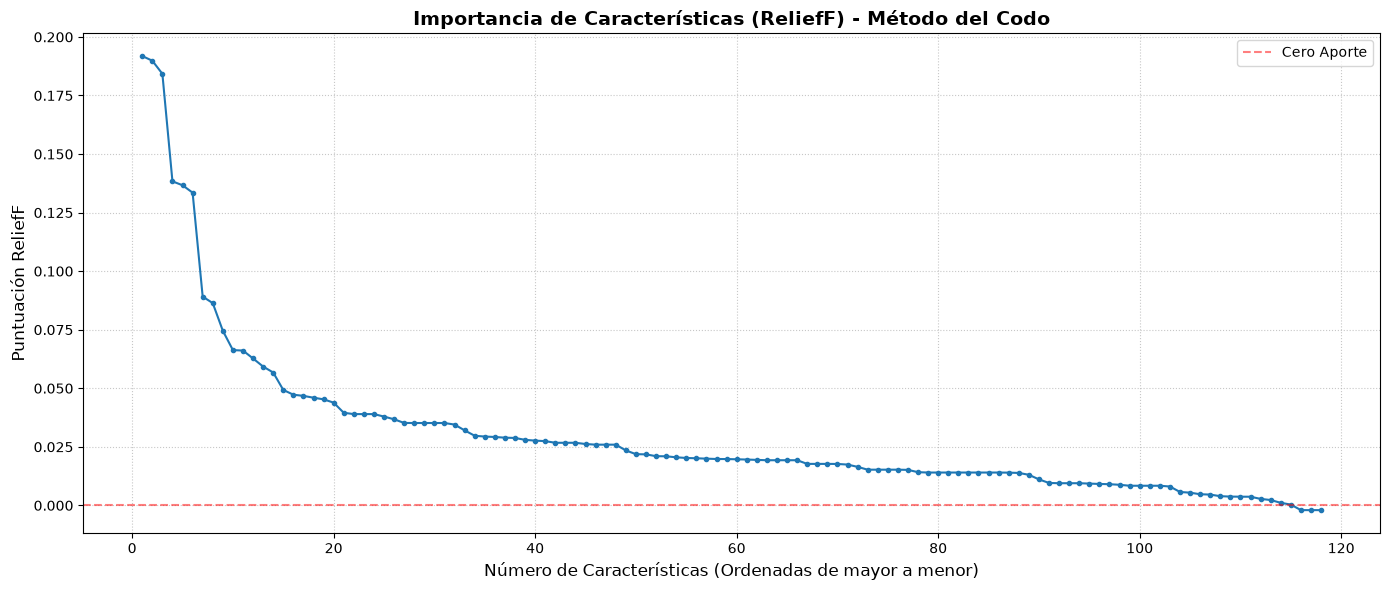

In [25]:
# Visualización para encontrar el "Codo" (Optimal Number of Features)
plt.figure(figsize=(14, 6))
plt.plot(range(1, len(relief_scores) + 1), relief_scores['Score'], marker='.', linestyle='-')
plt.title('Importancia de Características (ReliefF) - Método del Codo', fontweight='bold', fontsize=14)
plt.xlabel('Número de Características (Ordenadas de mayor a menor)', fontsize=12)
plt.ylabel('Puntuación ReliefF', fontsize=12)

# Líneas guía visuales
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Cero Aporte')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

In [26]:
# Visualización de las 30 características con mayor puntuación ReliefF
print("\n--- TOP 30 CARACTERÍSTICAS SEGÚN RELIEF ---")
relief_scores.head(30)


--- TOP 30 CARACTERÍSTICAS SEGÚN RELIEF ---


,Feature,Score
19,EDA_SCL_max,0.191845
16,EDA_SCL_mean,0.189847
18,EDA_SCL_min,0.184265
55,EDA_SCL_C_max,0.138345
52,EDA_SCL_C_mean,0.136683
54,EDA_SCL_C_min,0.133518
95,ECG_bpm,0.089145
96,ECG_ibi,0.086363
108,Resp_C_rate,0.074564
111,Resp_C_Exhal_mean,0.066299


Mediante la inspección visual de la curva de importancia (Método del Codo), se observa un punto de inflexión en el atributo 18, a partir del cual la ganancia informativa marginal disminuye considerablemente.

In [27]:
# Seleccionar las 18 mejores características según ReliefF
top_18_features = relief_scores['Feature'].head(18).tolist()
X_selected = X_res[top_18_features]

#### 4.2.4 Interpretación de la selección de características <a id="s4-2-4"></a>

Selección de Características (ReliefF a 18 variables): Al reducir de 118 a 18 características, eliminamos la redundancia y el ruido colineal. ReliefF fue elegido por su capacidad matemática para evaluar interacciones complejas entre variables y distinguir entre instancias vecinas de distintas clases.

## 5. Modeling <a id="s5"></a>

### 5.1 Random Forest con ruido (todas las variables) <a id="s5-1"></a>

In [28]:
# Configuración del Algoritmo y Validación Cruzada
# Usamos class_weight='balanced' para contrarrestar el desbalanceo de clases (0, 1, 2)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#Accuracy, F1-Score (ponderado por el desbalanceo) y AUC (One-vs-Rest)
scoring_metrics = {'ACC': 'accuracy', 'F1': 'f1_weighted', 'AUC': 'roc_auc_ovr_weighted'}
results_list = []

In [29]:
# Bucle de Evaluación para el Baseline y cada nivel de Ruido (SNR)
for snr_name, X_noisy in noisy_X_dict.items():
    print(f"Entrenando y evaluando dataset: {snr_name}...")
    
    # Validación cruzada estricta
    cv_results = cross_validate(rf_model, X_noisy, y, cv=cv_stratified, scoring=scoring_metrics)
    
    # Extracción de la media de las métricas en los 5 pliegues
    results_list.append({
        'SNR': snr_name,
        'Accuracy': cv_results['test_ACC'].mean(),
        'F1_Score': cv_results['test_F1'].mean(),
        'AUC': cv_results['test_AUC'].mean()
    })

# Consolidación de Resultados en un DataFrame
results_df = pd.DataFrame(results_list)
print("\n--- RESULTADOS FINALES DE DEGRADACIÓN ---")
results_df

Entrenando y evaluando dataset: 0.01...
Entrenando y evaluando dataset: 0.1...
Entrenando y evaluando dataset: 0.15...
Entrenando y evaluando dataset: 0.4...
Entrenando y evaluando dataset: 0.6...
Entrenando y evaluando dataset: Baseline...

--- RESULTADOS FINALES DE DEGRADACIÓN ---


,SNR,Accuracy,F1_Score,AUC
0,0.01,0.505967,0.449131,0.555959
1,0.1,0.660225,0.606816,0.736084
2,0.15,0.684588,0.639607,0.797758
3,0.4,0.774693,0.739793,0.872362
4,0.6,0.793688,0.757830,0.906100
5,Baseline,0.968846,0.968881,0.998111


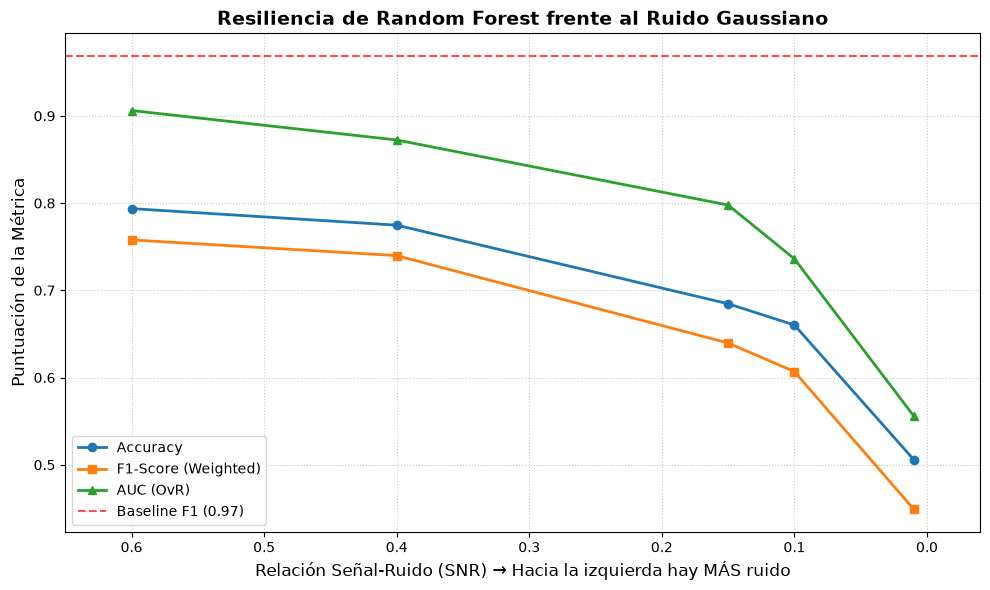

In [30]:
# Visualización de la Degradación del Rendimiento
# Separamos el Baseline de los valores numéricos de SNR para la gráfica
numeric_results = results_df[results_df['SNR'] != 'Baseline'].copy()
numeric_results['SNR'] = numeric_results['SNR'].astype(float)
# Ordenamos de menor ruido (0.6) a mayor ruido extremo (0.01)
numeric_results = numeric_results.sort_values(by='SNR', ascending=False) 

baseline_f1 = results_df[results_df['SNR'] == 'Baseline']['F1_Score'].values[0]
baseline_auc = results_df[results_df['SNR'] == 'Baseline']['AUC'].values[0]

plt.figure(figsize=(10, 6))
plt.plot(numeric_results['SNR'], numeric_results['Accuracy'], marker='o', linewidth=2, label='Accuracy')
plt.plot(numeric_results['SNR'], numeric_results['F1_Score'], marker='s', linewidth=2, label='F1-Score (Weighted)')
plt.plot(numeric_results['SNR'], numeric_results['AUC'], marker='^', linewidth=2, label='AUC (OvR)')

# Línea base de referencia (El techo de rendimiento sin ruido)
plt.axhline(y=baseline_f1, color='red', linestyle='--', alpha=0.7, label=f'Baseline F1 ({baseline_f1:.2f})')

plt.title('Resiliencia de Random Forest frente al Ruido Gaussiano', fontsize=14, fontweight='bold')
plt.xlabel('Relación Señal-Ruido (SNR) → Hacia la izquierda hay MÁS ruido', fontsize=12)
plt.ylabel('Puntuación de la Métrica', fontsize=12)
# Invertimos el eje X para que visualmente la curva "caiga" conforme aumenta el ruido
plt.xlim(max(numeric_results['SNR']) + 0.05, min(numeric_results['SNR']) - 0.05) 
plt.legend(loc='lower left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()


--- GENERANDO CURVAS ROC (BASELINE) ---


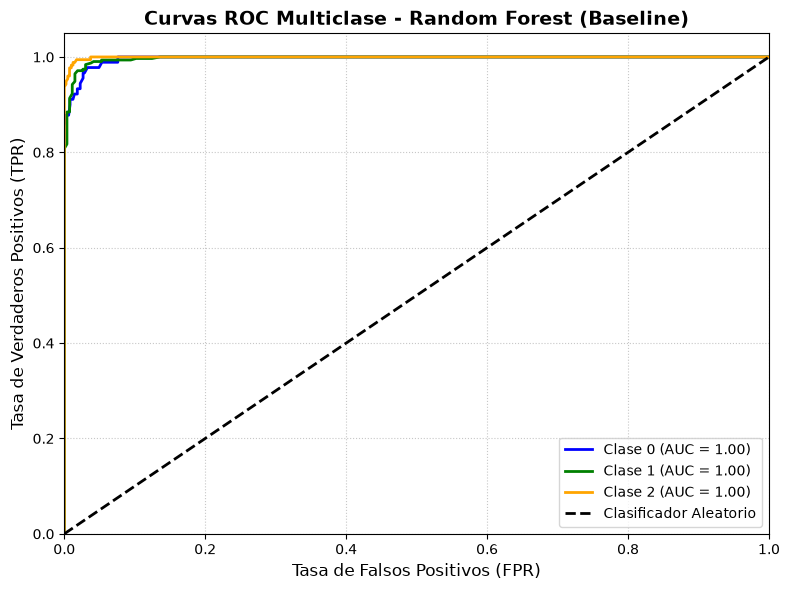

In [31]:
# Generación de Curvas ROC para el Modelo Baseline (Multiclase)
print("\n--- GENERANDO CURVAS ROC (BASELINE) ---")
# Binarizamos las etiquetas para cálculo multiclase One-vs-Rest
y_bin = label_binarize(y, classes=[0, 1, 2])
n_classes = y_bin.shape[1]

# Obtenemos las probabilidades predictivas con validación cruzada sobre los datos limpios
y_prob = cross_val_predict(rf_model, noisy_X_dict['Baseline'], y, cv=cv_stratified, method='predict_proba')

plt.figure(figsize=(8, 6))
colors = ['blue', 'green', 'orange']
for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'Clase {i} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Clasificador Aleatorio')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
plt.title('Curvas ROC Multiclase - Random Forest (Baseline)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

#### 5.1.1 Interpretación de la robustez al ruido <a id="s5-1-1"></a>

**Rendimiento Óptimo en Condiciones Ideales (Baseline)**

La gráfica de Curvas ROC Multiclase demuestra empíricamente que, en un entorno de laboratorio controlado (datos limpios o Baseline), el Random Forest posee una capacidad discriminativa matemáticamente casi perfecta. Las tres clases alcanzan un Área Bajo la Curva (AUC) de 1.00 (0.998 en la tabla general) y un F1-Score ponderado de 0.97. Esto confirma que las características fisiológicas extraídas (especialmente la varianza de la conductancia de la piel y el ritmo cardíaco) contienen la información exacta y necesaria para separar los tres estados (reposo, emoción positiva y estrés) de forma contundente.

**Cuantificación de la Degradación por Interferencia Ambiental**

A pesar del excelente desempeño inicial, la gráfica de línea (Resiliencia frente al Ruido) y la tabla resumen demuestran la vulnerabilidad del modelo tradicional ante escenarios que simulan el mundo real. Se observa una caída monotónica y severa en todas las métricas de evaluación a medida que disminuye la Relación Señal-Ruido (SNR):

Ruido Leve/Moderado (SNR 0.6 y 0.4): La inyección de la primera capa de ruido provoca una caída inmediata del F1-Score desde 0.97 hasta 0.77 y 0.69, respectivamente. El modelo comienza a confundir las clases debido a que la interferencia oscurece los umbrales de decisión de los árboles.

Ruido Severo a Extremo (SNR ≤ 0.15): A partir de un SNR de 0.15, el modelo entra en un declive crítico, cayendo por debajo del 70% de Accuracy. En el nivel de ruido más extremo simulado (SNR 0.01), el algoritmo colapsa por completo: su Accuracy cae a 0.51 y su AUC a 0.52. En este punto, la varianza del ruido ha ahogado totalmente la señal biológica, dejando al Random Forest con un AUC prácticamente igual al azar (0.5) y con una Accuracy inferior al 54.1 % que lograría un clasificador que predijera siempre la clase mayoritaria (clase 1).

**Justificación para el Avance Metodológico**

Estos resultados prueban la hipótesis central derivada de la revisión bibliográfica: los algoritmos entrenados en entornos perfectos sufren una degradación crítica al enfrentarse al ruido inherente de los sensores portátiles (wearables) en la vida diaria. Aunque Random Forest demostró ser un ensamble poderoso en condiciones limpias, su vulnerabilidad ante interferencias severas deja un margen inaceptable para el diagnóstico clínico de la ansiedad en el mundo real.

> **Nota de reproducibilidad:** el Noise Engine no fija una semilla aleatoria; los valores citados corresponden a la ejecución guardada en este cuaderno y pueden variar ligeramente al volver a ejecutarlo.


### 5.2 Random Forest optimizado (18 variables, StratifiedGroupKFold) <a id="s5-2"></a>

#### 5.2.1 Validación cruzada por grupos y grilla de hiperparámetros <a id="s5-2-1"></a>

In [32]:
# Configuración de StratifiedGroupKFold (Prevención de fuga de datos entre pacientes)
# Asegura que un paciente (subject) esté en Train o en Test, pero nunca en ambos
cv_sgkf = StratifiedGroupKFold(n_splits=5)

# Configurar el Random Forest y la grilla de hiperparámetros
rf_base = RandomForestClassifier(random_state=42, class_weight='balanced')

param_grid = {
    'n_estimators': [50, 100, 200],         # Cantidad de árboles
    'max_depth': [None, 10, 20],            # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],        # Muestras mínimas para dividir un nodo
    'min_samples_leaf': [1, 2, 4]           # Muestras mínimas en una hoja final
}

#### 5.2.2 Búsqueda de hiperparámetros (GridSearchCV) <a id="s5-2-2"></a>

In [33]:

print("Buscando los mejores hiperparámetros (esto puede tomar un par de minutos)...")
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=cv_sgkf,
    scoring='f1_weighted', # Optimizamos buscando el mejor F1-Score
    n_jobs=2,   # limitar workers evita "paging file too small" en Windows
    verbose=1
)

Buscando los mejores hiperparámetros (esto puede tomar un par de minutos)...


In [34]:
# joblib con backend "threading" comparte memoria con el proceso principal:
# evita que cada worker intente cargar cublas64_12.dll por separado
# (causa del WinError 1455 "paging file too small").
from joblib import parallel_backend
with parallel_backend("threading"):
    grid_search.fit(X_selected, y_res, groups=groups_res)

# Resultados del mejor modelo
best_rf = grid_search.best_estimator_

print("\n--- MEJORES HIPERPARÁMETROS ENCONTRADOS ---")
for param, value in grid_search.best_params_.items():
    print(f" - {param}: {value}")

print(f"\nF1-Score (Weighted) Promedio en Validación Cruzada: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 81 candidates, totalling 405 fits

--- MEJORES HIPERPARÁMETROS ENCONTRADOS ---
 - max_depth: None
 - min_samples_leaf: 4
 - min_samples_split: 10
 - n_estimators: 200

F1-Score (Weighted) Promedio en Validación Cruzada: 0.8692


#### 5.2.3 Reporte de clasificación del mejor modelo <a id="s5-2-3"></a>

In [35]:
# Evaluación detallada con el mejor modelo (Reporte Final)
print("\n--- REPORTE DE CLASIFICACIÓN FINAL (BEST MODEL) ---")
# Generamos predicciones cruzadas guardándolas con NOMBRES ÚNICOS
y_pred_rf_opt = cross_val_predict(best_rf, X_selected, y_res, cv=cv_sgkf, groups=groups_res)
y_prob_rf_opt = cross_val_predict(best_rf, X_selected, y_res, cv=cv_sgkf, groups=groups_res, method='predict_proba')

print(classification_report(y_res, y_pred_rf_opt))

# Cálculo de AUC Multiclase (One-vs-Rest)
y_res_bin = label_binarize(y_res, classes=[0, 1, 2])
auc_score_rf_opt = roc_auc_score(y_res_bin, y_prob_rf_opt, average='weighted', multi_class='ovr')
print(f"AUC (One-vs-Rest Ponderado): {auc_score_rf_opt:.4f}")
print(f"Accuracy Global: {accuracy_score(y_res, y_pred_rf_opt):.4f}")


--- REPORTE DE CLASIFICACIÓN FINAL (BEST MODEL) ---
              precision    recall  f1-score   support

           0       0.78      0.94      0.85        90
           1       0.93      0.69      0.79        90
           2       0.95      0.99      0.97        90

    accuracy                           0.87       270
   macro avg       0.88      0.87      0.87       270
weighted avg       0.88      0.87      0.87       270

AUC (One-vs-Rest Ponderado): 0.9530
Accuracy Global: 0.8741


#### 5.2.4 Interpretación del Random Forest optimizado <a id="s5-2-4"></a>

Robustez Clínica (StratifiedGroupKFold): Justifica el cambio del StratifiedKFold normal al StratifiedGroupKFold como una medida vital para evaluar la generalización clínica. Esto garantiza que el modelo evalúa su rendimiento prediciendo datos de sujetos completamente nuevos, evitando el sesgo de memorización del ritmo cardíaco base de un paciente específico.

Optimización (GridSearchCV): En lugar de usar valores por defecto, se barrió exhaustivamente una matriz de combinaciones de hiperparámetros para encontrar la configuración que maximiza estrictamente el F1-Score ponderado, estableciendo así el modelo base optimizado para su evaluación frente a los Modelos Fundacionales Tabulares.

### 5.3 TabICL (v1) - Reducción de variables a 18 <a id="s5-3"></a>

In [36]:
# Inicialización del clasificador TabICL (inferencia Zero-Shot) con el checkpoint de la v1
tabicl_model = TabICLClassifier(
    checkpoint_version="tabicl-classifier-v1-20250208.ckpt",
    **kw_gpu(TabICLClassifier, device=DEVICE)
)

print("Realizando inferencia In-Context Learning con TabICL en GPU...")
start_time = time.time()

# Una sola pasada por la GPU: probabilidades (AUC) y predicción = argmax (antes eran 2 pasadas completas)
y_prob_tabicl = cross_val_predict(tabicl_model, X_selected, y_res, cv=cv_sgkf, groups=groups_res, method='predict_proba')
y_pred_tabicl = np.sort(np.unique(y_res))[np.argmax(y_prob_tabicl, axis=1)]
liberar_gpu()

end_time = time.time()
print(f"\nInferencia completada en {end_time - start_time:.2f} segundos.")

print("\n--- REPORTE DE CLASIFICACIÓN (TabICL - BASELINE) ---")
print(classification_report(y_res, y_pred_tabicl))

acc_tabicl = accuracy_score(y_res, y_pred_tabicl)
print(f"Accuracy Global: {acc_tabicl:.4f}")

y_res_bin = label_binarize(y_res, classes=[0, 1, 2])
auc_tabicl = roc_auc_score(y_res_bin, y_prob_tabicl, average='weighted', multi_class='ovr')
print(f"AUC (One-vs-Rest Ponderado): {auc_tabicl:.4f}")

f1_tabicl = f1_score(y_res, y_pred_tabicl, average='weighted')  # F1 ponderado de TabICL v1

TabICLClassifier: parámetros GPU aplicados -> {'device': 'cuda'}
Realizando inferencia In-Context Learning con TabICL en GPU...

Inferencia completada en 7.62 segundos.

--- REPORTE DE CLASIFICACIÓN (TabICL - BASELINE) ---
              precision    recall  f1-score   support

           0       0.81      0.70      0.75        90
           1       0.74      0.80      0.77        90
           2       0.93      0.98      0.95        90

    accuracy                           0.83       270
   macro avg       0.83      0.83      0.82       270
weighted avg       0.83      0.83      0.82       270

Accuracy Global: 0.8259
AUC (One-vs-Rest Ponderado): 0.9460


#### 5.3.1 Interpretación de TabICL (v1) <a id="s5-3-1"></a>

Eficacia en la Reducción de Dimensionalidad: Al reducir la dimensionalidad del conjunto de datos original en un 85% (de 118 a 18 características), el modelo logró mantener un poder predictivo altamente competitivo. Esto confirma que ReliefF aisló exitosamente los biomarcadores más relevantes, limpiando el ruido colineal innecesario.

Rendimiento Zero-Shot del Modelo Fundacional: TabICL (v1) alcanzó un Área Bajo la Curva (AUC) ponderada de 0.9460 y una exactitud global (Accuracy) del 82.6%. Este desempeño es notablemente robusto dado que fue evaluado bajo un esquema StratifiedGroupKFold, garantizando que el algoritmo generaliza correctamente frente a la fisiología de sujetos completamente nuevos, sin caer en la fuga de datos.

### 5.4 TabICL (v2) <a id="s5-4"></a>

In [37]:
print("--- INICIANDO MODELADO CON TRANSFORMER TABULAR (TabICLv2) ---")

# 1. Inicialización del modelo (Zero-Shot) con el checkpoint de la v2
tabiclv2_model = TabICLClassifier(
    checkpoint_version="tabicl-classifier-v2-20260212.ckpt",
    **kw_gpu(TabICLClassifier, device=DEVICE)
)

print("Realizando inferencia In-Context Learning con TabICLv2...")
start_time = time.time()

# 2. Generación de Predicciones
# Una sola pasada por la GPU: probabilidades y predicción = argmax
y_prob_tabiclv2 = cross_val_predict(tabiclv2_model, X_selected, y_res, cv=cv_sgkf, groups=groups_res, method='predict_proba')
y_pred_tabiclv2 = np.sort(np.unique(y_res))[np.argmax(y_prob_tabiclv2, axis=1)]
liberar_gpu()

print(f"Inferencia completada en {time.time() - start_time:.2f} segundos.\n")

# 3. Cálculo de métricas
acc_tabiclv2 = accuracy_score(y_res, y_pred_tabiclv2)
f1_tabiclv2 = f1_score(y_res, y_pred_tabiclv2, average='weighted')
y_res_bin = label_binarize(y_res, classes=[0, 1, 2])
auc_tabiclv2 = roc_auc_score(y_res_bin, y_prob_tabiclv2, average='weighted', multi_class='ovr')

print("--- REPORTE DE CLASIFICACIÓN (TabICLv2 - BASELINE) ---")
print(classification_report(y_res, y_pred_tabiclv2))
print(f"Accuracy: {acc_tabiclv2:.4f} | F1-Score: {f1_tabiclv2:.4f} | AUC: {auc_tabiclv2:.4f}")

--- INICIANDO MODELADO CON TRANSFORMER TABULAR (TabICLv2) ---
TabICLClassifier: parámetros GPU aplicados -> {'device': 'cuda'}
Realizando inferencia In-Context Learning con TabICLv2...
Inferencia completada en 3.99 segundos.

--- REPORTE DE CLASIFICACIÓN (TabICLv2 - BASELINE) ---
              precision    recall  f1-score   support

           0       0.79      0.74      0.77        90
           1       0.80      0.78      0.79        90
           2       0.91      0.99      0.95        90

    accuracy                           0.84       270
   macro avg       0.83      0.84      0.83       270
weighted avg       0.83      0.84      0.83       270

Accuracy: 0.8370 | F1-Score: 0.8345 | AUC: 0.9493


### 5.5 Mitra <a id="s5-5"></a>

In [38]:
start_time = time.time()
y_res_bin = label_binarize(y_res, classes=[0, 1, 2])

y_pred_mitra = np.zeros(len(y_res), dtype=int)
y_prob_mitra = np.zeros((len(y_res), 3), dtype=float)

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_selected, y_res, groups=groups_res)):
    X_train_fold, X_test_fold = X_selected.iloc[train_idx], X_selected.iloc[test_idx]
    y_train_fold = y_res.iloc[train_idx]
    
    if usar_sklearn_mitra:
        # Configuración Zero-Shot (fine_tune=False) fiel al paper
        mitra_clf = MitraClassifier(fine_tune=False, **kw_gpu(MitraClassifier, device=DEVICE))
        mitra_clf.fit(X_train_fold, y_train_fold)
        y_pred_mitra[test_idx] = mitra_clf.predict(X_test_fold)
        y_prob_mitra[test_idx] = mitra_clf.predict_proba(X_test_fold)
    else:
        train_df = X_train_fold.copy()
        train_df['target'] = y_train_fold.values
        predictor = TabularPredictor(label='target', verbosity=0, path=f'AutogluonModels/mitra_fold_{fold}')
        predictor.fit(train_df, hyperparameters={'MITRA': {'fine_tune': False}},
                      num_gpus=1 if DEVICE == 'cuda' else 0)
        y_pred_mitra[test_idx] = predictor.predict(X_test_fold).values
        y_prob_mitra[test_idx] = predictor.predict_proba(X_test_fold).values

liberar_gpu()

acc_mitra = accuracy_score(y_res, y_pred_mitra)
f1_mitra = f1_score(y_res, y_pred_mitra, average='weighted')
auc_mitra = roc_auc_score(y_res_bin, y_prob_mitra, average='weighted', multi_class='ovr')

print(f"Inferencia de Mitra completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (Mitra - BASELINE) ---")
print(classification_report(y_res, y_pred_mitra))
print(f"Accuracy: {acc_mitra:.4f} | F1-Score: {f1_mitra:.4f} | AUC: {auc_mitra:.4f}\n")

MitraClassifier: parámetros GPU aplicados -> {'device': 'cuda'}


2026-11-10 16:21:52.869 | INFO     | autogluon.tabular.models.mitra._internal.core.trainer_finetune:log_start_metrics:375 - Epoch 000 | Train CE: -.---- | Train acc: -.---- | Val CE: 0.2195 | Val acc: 0.9070


MitraClassifier: parámetros GPU aplicados -> {'device': 'cuda'}


2026-11-10 16:21:54.727 | INFO     | autogluon.tabular.models.mitra._internal.core.trainer_finetune:log_start_metrics:375 - Epoch 000 | Train CE: -.---- | Train acc: -.---- | Val CE: 0.2394 | Val acc: 0.9302


MitraClassifier: parámetros GPU aplicados -> {'device': 'cuda'}


2026-11-10 16:21:56.315 | INFO     | autogluon.tabular.models.mitra._internal.core.trainer_finetune:log_start_metrics:375 - Epoch 000 | Train CE: -.---- | Train acc: -.---- | Val CE: 0.2638 | Val acc: 0.8864


MitraClassifier: parámetros GPU aplicados -> {'device': 'cuda'}


2026-11-10 16:21:57.927 | INFO     | autogluon.tabular.models.mitra._internal.core.trainer_finetune:log_start_metrics:375 - Epoch 000 | Train CE: -.---- | Train acc: -.---- | Val CE: 0.1107 | Val acc: 0.9767


MitraClassifier: parámetros GPU aplicados -> {'device': 'cuda'}


2026-11-10 16:21:59.531 | INFO     | autogluon.tabular.models.mitra._internal.core.trainer_finetune:log_start_metrics:375 - Epoch 000 | Train CE: -.---- | Train acc: -.---- | Val CE: 0.0827 | Val acc: 1.0000


Inferencia de Mitra completada en 25.32 segundos.
--- REPORTE DE CLASIFICACIÓN (Mitra - BASELINE) ---
              precision    recall  f1-score   support

           0       0.74      0.77      0.75        90
           1       0.82      0.73      0.78        90
           2       0.88      0.94      0.91        90

    accuracy                           0.81       270
   macro avg       0.81      0.81      0.81       270
weighted avg       0.81      0.81      0.81       270

Accuracy: 0.8148 | F1-Score: 0.8132 | AUC: 0.9317



### 5.6 Preparación de matrices NumPy para los modelos en GPU <a id="s5-6"></a>

In [39]:
# Matrices NumPy base (usadas por TabDPT, TabPFN, TabFM, iLTM y EXAONE-Tabular)
X_np = X_selected.values.astype(np.float32)
y_np = y_res.values.astype(int)
n_clases = len(np.unique(y_np))
print(f"Dispositivo activo: {DEVICE.upper()} | X: {X_np.shape} | clases: {n_clases}")


Dispositivo activo: CUDA | X: (270, 18) | clases: 3


In [40]:
# Verificación rápida de que los modelos tienen acceso a la GPU
print("CUDA disponible:", torch.cuda.is_available(), "| Dispositivo:", DEVICE)
if DEVICE == "cuda":
    print("Memoria GPU en uso: %.2f GB" % (torch.cuda.memory_allocated() / 1024**3))

CUDA disponible: True | Dispositivo: cuda
Memoria GPU en uso: 0.29 GB


### 5.7 TabDPT <a id="s5-7"></a>

In [41]:
start_time = time.time()
y_pred_tabdpt = np.zeros(len(y_res), dtype=int)
y_prob_tabdpt = np.zeros((len(y_res), 3), dtype=float)

# TabDPT requiere arreglos de NumPy
X_np = X_selected.values.astype(np.float32)
y_np = y_res.values.astype(int)

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res)):
    tabdpt_model = TabDPTClassifier(**kw_gpu(TabDPTClassifier, device=DEVICE, compile=False,
                                             use_flash=not SDPA_SEGURO))
    tabdpt_model.fit(X_np[train_idx], y_np[train_idx])
    
    # Inferencia sobre el fold de validación
    probs = tabdpt_model.predict_proba(X_np[test_idx])
    y_prob_tabdpt[test_idx] = probs
    y_pred_tabdpt[test_idx] = np.argmax(probs, axis=1)
    liberar_gpu()

acc_tabdpt = accuracy_score(y_res, y_pred_tabdpt)
f1_tabdpt = f1_score(y_res, y_pred_tabdpt, average='weighted')
auc_tabdpt = roc_auc_score(y_res_bin, y_prob_tabdpt, average='weighted', multi_class='ovr')

print(f"Inferencia de TabDPT completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (TabDPT - BASELINE) ---")
print(classification_report(y_res, y_pred_tabdpt))
print(f"Accuracy: {acc_tabdpt:.4f} | F1-Score: {f1_tabdpt:.4f} | AUC: {auc_tabdpt:.4f}")

TabDPTClassifier: parámetros GPU aplicados -> {'device': 'cuda', 'compile': False, 'use_flash': False}
TabDPTClassifier: parámetros GPU aplicados -> {'device': 'cuda', 'compile': False, 'use_flash': False}
TabDPTClassifier: parámetros GPU aplicados -> {'device': 'cuda', 'compile': False, 'use_flash': False}
TabDPTClassifier: parámetros GPU aplicados -> {'device': 'cuda', 'compile': False, 'use_flash': False}
TabDPTClassifier: parámetros GPU aplicados -> {'device': 'cuda', 'compile': False, 'use_flash': False}
Inferencia de TabDPT completada en 7.37 segundos.
--- REPORTE DE CLASIFICACIÓN (TabDPT - BASELINE) ---
              precision    recall  f1-score   support

           0       0.82      0.66      0.73        90
           1       0.77      0.84      0.80        90
           2       0.90      0.99      0.94        90

    accuracy                           0.83       270
   macro avg       0.83      0.83      0.82       270
weighted avg       0.83      0.83      0.82       270

A

### 5.8 TabPFN <a id="s5-8"></a>

In [42]:
import faulthandler, pathlib
_fh = open("faulthandler_tabpfn.log", "w")
faulthandler.enable(file=_fh, all_threads=True)

# ── Autenticación de TabPFN ───────────────────────────────────────────────────
# TabPFN 9.x requiere un token de https://ux.priorlabs.ai/account
# Opción A (recomendada): ejecuta tabpfn_login.py una vez en Anaconda Prompt y
#   el token queda guardado; esta celda lo leerá automáticamente.
# Opción B: pega tu API key directamente aquí (entre las comillas) y descomenta:
os.environ["TABPFN_TOKEN"] = "tabpfn_sk_ue3lJgn-AcxBnpaR1I0U4UUDSFovbi-UeIc6VA01TY0"

_tabpfn_token_file = pathlib.Path.home() / ".tabpfn" / "token"
if _tabpfn_token_file.exists():
    os.environ["TABPFN_TOKEN"] = _tabpfn_token_file.read_text().strip()
    print(f"Token de TabPFN cargado desde {_tabpfn_token_file}")
elif "TABPFN_TOKEN" not in os.environ:
    raise EnvironmentError(
        "TabPFN necesita autenticación.\n"
        "Ejecuta en Anaconda Prompt:\n"
        "    conda activate TesisCONDA\n"
        "    python tabpfn_login.py\n"
        "O descomenta la línea TABPFN_TOKEN en esta celda y pega tu API Key."
    )
# ─────────────────────────────────────────────────────────────────────────────

DEVICE_TABPFN = DEVICE  #gpu
from tabpfn import TabPFNClassifier
import tabpfn
print("tabpfn", getattr(tabpfn, "__version__", "?"), "| torch", torch.__version__, "| dispositivo TabPFN:", DEVICE_TABPFN)
from huggingface_hub import hf_hub_download

start_time = time.time()
y_pred_tabpfn = np.zeros(len(y_res), dtype=int)
y_prob_tabpfn = np.zeros((len(y_res), n_clases), dtype=float)

# Descargar pesos públicos v2 para evitar el bloqueo de licencia interactiva
try:
    ruta_pesos_tabpfn = hf_hub_download(
        repo_id="Prior-Labs/TabPFN-v2-clf",
        filename="tabpfn-v2-classifier.ckpt"
    )
    kwargs_tabpfn = {"device": DEVICE_TABPFN, "model_path": ruta_pesos_tabpfn}
except Exception:
    # usar tu API Key de https://ux.priorlabs.ai/account:
    os.environ["TABPFN_TOKEN"] = "tabpfn_sk_ue3lJgn-AcxBnpaR1I0U4UUDSFovbi-UeIc6VA01TY0"
    kwargs_tabpfn = {"device": DEVICE_TABPFN}

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res), start=1):
    print(f"TabPFN - Procesando Fold {fold}/5...", flush=True)
    tabpfn_model = TabPFNClassifier(**kwargs_tabpfn)
    
    with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AUTOCAST):
        tabpfn_model.fit(X_np[train_idx], y_np[train_idx])
        probs = tabpfn_model.predict_proba(X_np[test_idx])
        
    y_prob_tabpfn[test_idx] = probs
    y_pred_tabpfn[test_idx] = np.argmax(probs, axis=1)
    liberar_gpu()

acc_tabpfn = accuracy_score(y_res, y_pred_tabpfn)
f1_tabpfn = f1_score(y_res, y_pred_tabpfn, average='weighted')
auc_tabpfn = roc_auc_score(y_res_bin, y_prob_tabpfn, average='weighted', multi_class='ovr')

print(f"\nInferencia de TabPFN completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (TabPFN) ---")
print(classification_report(y_res, y_pred_tabpfn))
print(f"Accuracy: {acc_tabpfn:.4f} | F1-Score: {f1_tabpfn:.4f} | AUC: {auc_tabpfn:.4f}")

tabpfn 9.2.0 | torch 2.11.0+cu128 | dispositivo TabPFN: cuda
TabPFN - Procesando Fold 1/5...
TabPFN - Procesando Fold 2/5...
TabPFN - Procesando Fold 3/5...
TabPFN - Procesando Fold 4/5...
TabPFN - Procesando Fold 5/5...

Inferencia de TabPFN completada en 3.96 segundos.
--- REPORTE DE CLASIFICACIÓN (TabPFN) ---
              precision    recall  f1-score   support

           0       0.75      0.63      0.69        90
           1       0.71      0.78      0.74        90
           2       0.91      0.97      0.94        90

    accuracy                           0.79       270
   macro avg       0.79      0.79      0.79       270
weighted avg       0.79      0.79      0.79       270

Accuracy: 0.7926 | F1-Score: 0.7890 | AUC: 0.9330


### 5.9 TabFM <a id="s5-9"></a>

In [43]:
from tabfm import TabFMClassifier
from tabfm import tabfm_v1_0_0_pytorch as tabfm_v1_0_0

start_time = time.time()
y_pred_tabfm = np.zeros(len(y_res), dtype=int)
y_prob_tabfm = np.zeros((len(y_res), n_clases), dtype=float)

# Cargar pesos preentrenados una sola vez fuera del bucle
base_model_tabfm = tabfm_v1_0_0.load(device=DEVICE)

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res)):
    X_tr_df = X_selected.iloc[train_idx].reset_index(drop=True)
    X_te_df = X_selected.iloc[test_idx].reset_index(drop=True)
    y_tr_arr = y_np[train_idx]
    
    tabfm_model = TabFMClassifier(model=base_model_tabfm)
    
    with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AUTOCAST):
        tabfm_model.fit(X_tr_df, y_tr_arr)
        probs = tabfm_model.predict_proba(X_te_df)
        
    y_prob_tabfm[test_idx] = probs
    y_pred_tabfm[test_idx] = np.argmax(probs, axis=1)

acc_tabfm = accuracy_score(y_res, y_pred_tabfm)
f1_tabfm = f1_score(y_res, y_pred_tabfm, average='weighted')
auc_tabfm = roc_auc_score(y_res_bin, y_prob_tabfm, average='weighted', multi_class='ovr')

print(f"Inferencia de TabFM completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (TabFM) ---")
print(classification_report(y_res, y_pred_tabfm))
print(f"Accuracy: {acc_tabfm:.4f} | F1-Score: {f1_tabfm:.4f} | AUC: {auc_tabfm:.4f}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights from local directory
Inferencia de TabFM completada en 44.46 segundos.
--- REPORTE DE CLASIFICACIÓN (TabFM) ---
              precision    recall  f1-score   support

           0       0.81      0.60      0.69        90
           1       0.75      0.82      0.78        90
           2       0.86      0.99      0.92        90

    accuracy                           0.80       270
   macro avg       0.80      0.80      0.80       270
weighted avg       0.80      0.80      0.80       270

Accuracy: 0.8037 | F1-Score: 0.7962 | AUC: 0.9388


### 5.10 iLTM <a id="s5-10"></a>

In [44]:
from iltm import iLTMClassifier

start_time = time.time()
y_pred_iltm = np.zeros(len(y_res), dtype=int)
y_prob_iltm = np.zeros((len(y_res), n_clases), dtype=float)

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res), start=1):
    t_fold = time.time()
    print(f"iLTM - Entrenando Fold {fold}/5...")
    
    # Pocos pasos de fine-tuning (ejecución rápida); corre en GPU vía device=DEVICE
    iltm_model = iLTMClassifier(
        device=DEVICE,
        finetuning_max_steps=10,
        do_retrieval=False
    )
    
    with torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AUTOCAST):
        iltm_model.fit(
            X_np[train_idx], 
            y_np[train_idx],
            fit_max_time=30,
            return_partial_on_timeout=True
        )
        probs = iltm_model.predict_proba(X_np[test_idx])
        
    y_prob_iltm[test_idx] = probs
    y_pred_iltm[test_idx] = np.argmax(probs, axis=1)
    liberar_gpu()
    print(f"  -> Fold {fold} completado en {time.time() - t_fold:.1f}s")

acc_iltm = accuracy_score(y_res, y_pred_iltm)
f1_iltm = f1_score(y_res, y_pred_iltm, average='weighted')
auc_iltm = roc_auc_score(y_res_bin, y_prob_iltm, average='weighted', multi_class='ovr')

print(f"\nInferencia de iLTM completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (iLTM) ---")
print(classification_report(y_res, y_pred_iltm))
print(f"Accuracy: {acc_iltm:.4f} | F1-Score: {f1_iltm:.4f} | AUC: {auc_iltm:.4f}")

iLTM - Entrenando Fold 1/5...


  -> Fold 1 completado en 17.4s
iLTM - Entrenando Fold 2/5...


  -> Fold 2 completado en 11.7s
iLTM - Entrenando Fold 3/5...


  -> Fold 3 completado en 10.8s
iLTM - Entrenando Fold 4/5...


  -> Fold 4 completado en 12.7s
iLTM - Entrenando Fold 5/5...


  -> Fold 5 completado en 12.2s

Inferencia de iLTM completada en 64.78 segundos.
--- REPORTE DE CLASIFICACIÓN (iLTM) ---
              precision    recall  f1-score   support

           0       0.77      0.71      0.74        90
           1       0.79      0.79      0.79        90
           2       0.90      0.97      0.93        90

    accuracy                           0.82       270
   macro avg       0.82      0.82      0.82       270
weighted avg       0.82      0.82      0.82       270

Accuracy: 0.8222 | F1-Score: 0.8198 | AUC: 0.9546


### 5.11 EXAONE-Tabular <a id="s5-11"></a>

In [45]:
import time
import gc
import torch
import numpy as np
from exaonetabular import EXAONETabularClassifier
import exaonetabular.model.attention as exaone_attn
from torch.nn.attention import SDPBackend, sdpa_kernel as _orig_sdpa_kernel
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# 1. Forzar SDPBackend.MATH dentro de EXAONE para evitar "RuntimeError: No available kernel" en RTX 5060
exaone_attn.sdpa_kernel = lambda *args, **kwargs: _orig_sdpa_kernel([SDPBackend.MATH])

# Asegurar función de limpieza de GPU
def _limpiar_vram():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.empty_cache()

_limpiar_vram()
start_time = time.time()
y_pred_exaone = np.zeros(len(y_res), dtype=int)
y_prob_exaone = np.zeros((len(y_res), n_clases), dtype=float)

DEVICE_EXAONE = DEVICE  # Ejecución directa en CUDA

for fold, (train_idx, test_idx) in enumerate(cv_sgkf.split(X_np, y_np, groups=groups_res), start=1):
    print(f"EXAONE-Tabular ({DEVICE_EXAONE.upper()}) - Procesando Fold {fold}/5...")
    exaone_model = EXAONETabularClassifier.from_pretrained(device=DEVICE_EXAONE)
    exaone_model.fit(X_np[train_idx], y_np[train_idx])

    probs = exaone_model.predict_proba(X_np[test_idx])
    y_prob_exaone[test_idx] = probs
    y_pred_exaone[test_idx] = np.argmax(probs, axis=1)

    del exaone_model
    _limpiar_vram()

acc_exaone = accuracy_score(y_res, y_pred_exaone)
f1_exaone = f1_score(y_res, y_pred_exaone, average='weighted')
auc_exaone = roc_auc_score(y_res_bin, y_prob_exaone, average='weighted', multi_class='ovr')

print(f"\nInferencia de EXAONE-Tabular completada en {time.time() - start_time:.2f} segundos.")
print("--- REPORTE DE CLASIFICACIÓN (EXAONE-Tabular) ---")
print(classification_report(y_res, y_pred_exaone))
print(f"Accuracy: {acc_exaone:.4f} | F1-Score: {f1_exaone:.4f} | AUC: {auc_exaone:.4f}")

EXAONE-Tabular (CUDA) - Procesando Fold 1/5...


EXAONE-Tabular (CUDA) - Procesando Fold 2/5...


EXAONE-Tabular (CUDA) - Procesando Fold 3/5...


EXAONE-Tabular (CUDA) - Procesando Fold 4/5...


EXAONE-Tabular (CUDA) - Procesando Fold 5/5...



Inferencia de EXAONE-Tabular completada en 8.38 segundos.
--- REPORTE DE CLASIFICACIÓN (EXAONE-Tabular) ---
              precision    recall  f1-score   support

           0       0.79      0.69      0.74        90
           1       0.78      0.80      0.79        90
           2       0.88      0.98      0.93        90

    accuracy                           0.82       270
   macro avg       0.82      0.82      0.82       270
weighted avg       0.82      0.82      0.82       270

Accuracy: 0.8222 | F1-Score: 0.8185 | AUC: 0.9434


## 6. Evaluation <a id="s6"></a>

### 6.1 Comparativa de modelos <a id="s6-1"></a>

#### 6.1.1 Métricas globales y gráfico comparativo <a id="s6-1-1"></a>

=== COMPARATIVA CONSOLIDADA (9 MODELOS ) ===


,Modelo,Familia_Enfoque,Accuracy,F1-Score (Weighted),ROC-AUC (OvR)
0,Random Forest (Optimizado),Ensamble tradicional,0.8741,0.8705,0.9530
1,TabICL (v2),TFM - Prior sintético mejorado,0.8370,0.8345,0.9493
2,TabDPT,TFM - Datos reales,0.8296,0.8248,0.9518
3,TabICL (v1),TFM - Prior sintético,0.8259,0.8238,0.9460
4,iLTM,TFM - Integrado (árboles+MLP),0.8222,0.8198,0.9546
5,EXAONE-Tabular,TFM - CAST,0.8222,0.8185,0.9434
6,Mitra,TFM - Prior mixto,0.8148,0.8132,0.9317
7,TabFM,TFM - Foundation Model,0.8037,0.7962,0.9388
8,TabPFN,TFM - Prior sintético,0.7926,0.7890,0.9330


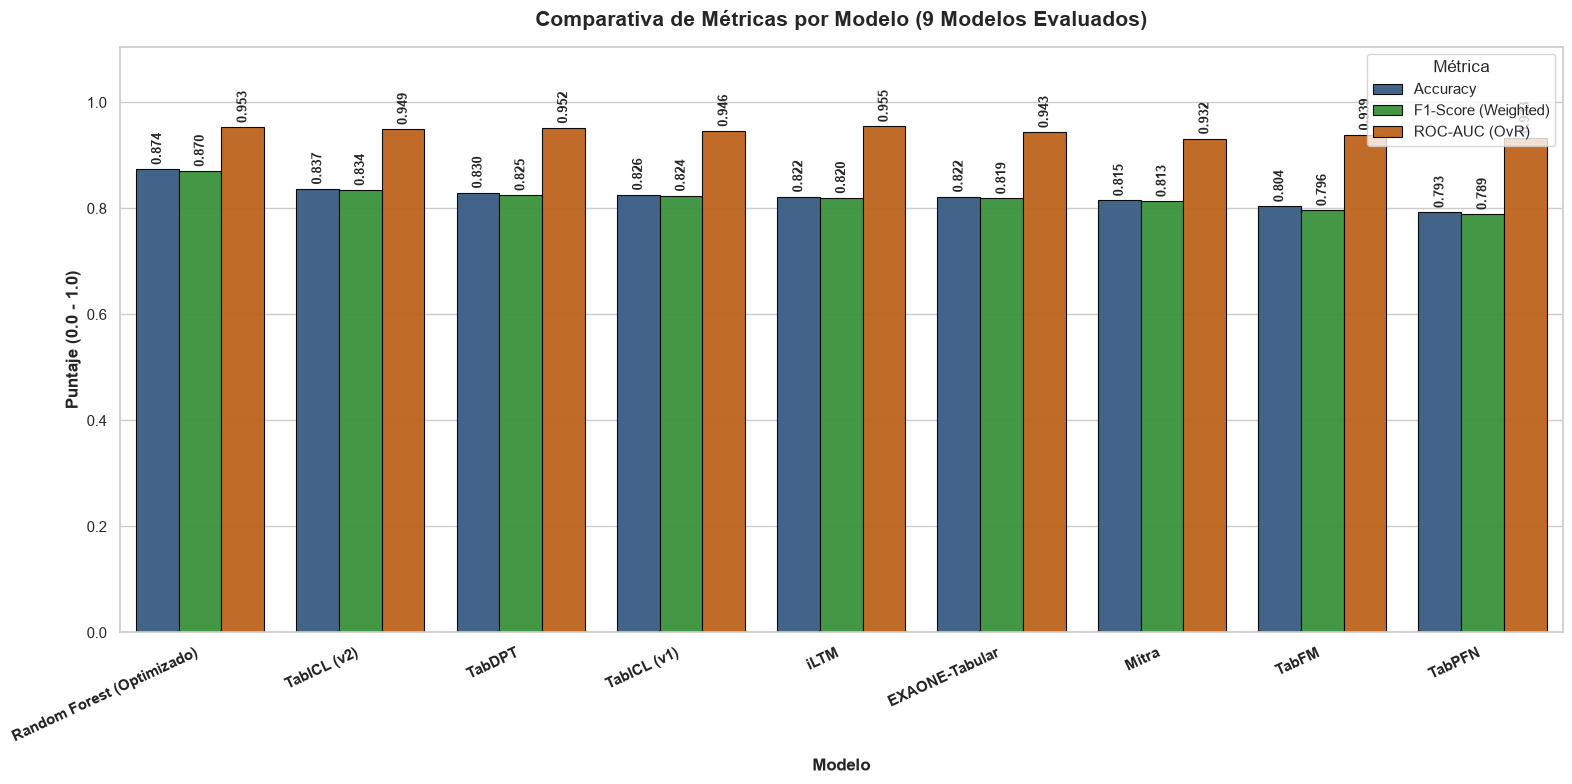

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize

# 1. Catálogo completo de los 9 modelos de la tesis
CATALOGO_COMPLETO = [
    ("Random Forest (Optimizado)", "Ensamble tradicional",         "y_pred_rf_opt",   "y_prob_rf_opt"),
    ("iLTM",                       "TFM - Integrado (árboles+MLP)","y_pred_iltm",     "y_prob_iltm"),
    ("TabDPT",                     "TFM - Datos reales",           "y_pred_tabdpt",   "y_prob_tabdpt"),
    ("TabICL (v2)",                "TFM - Prior sintético mejorado", "y_pred_tabiclv2", "y_prob_tabiclv2"),
    ("TabICL (v1)",                "TFM - Prior sintético",        "y_pred_tabicl",   "y_prob_tabicl"),
    ("EXAONE-Tabular",             "TFM - CAST",                   "y_pred_exaone",   "y_prob_exaone"),
    ("TabFM",                      "TFM - Foundation Model",       "y_pred_tabfm",    "y_prob_tabfm"),
    ("Mitra",                      "TFM - Prior mixto",            "y_pred_mitra",    "y_prob_mitra"),
    ("TabPFN",                     "TFM - Prior sintético",        "y_pred_tabpfn",   "y_prob_tabpfn"),
]

g = globals()
y_true = np.asarray(y_res)
y_true_bin = label_binarize(y_true, classes=[0, 1, 2])

filas, omitidos = [], []
for nombre, familia, v_pred, v_prob in CATALOGO_COMPLETO:
    # Búsqueda flexible de nombres alternativos si la variable exacta no existe
    p_encontrado, pr_encontrado = None, None
    for vp_cand in [v_pred, v_pred.replace("_", ""), v_pred.replace("v2", "2")]:
        if vp_cand in g:
            p_encontrado = g[vp_cand]
            break
    for vpr_cand in [v_prob, v_prob.replace("_", ""), v_prob.replace("v2", "2")]:
        if vpr_cand in g:
            pr_encontrado = g[vpr_cand]
            break
            
    if p_encontrado is None or pr_encontrado is None:
        omitidos.append(f"{nombre} (No se encontró {v_pred} o {v_prob} en memoria)")
        continue
        
    yp, pr = np.asarray(p_encontrado), np.asarray(pr_encontrado)
    
    if len(yp) != len(y_true) or len(pr) != len(y_true):
        omitidos.append(f"{nombre} (Error de dimensiones)")
        continue
        
    filas.append({
        "Modelo": nombre,
        "Familia_Enfoque": familia,
        "Accuracy": accuracy_score(y_true, yp),
        "F1-Score (Weighted)": f1_score(y_true, yp, average="weighted", zero_division=0),
        "ROC-AUC (OvR)": roc_auc_score(y_true_bin, pr, average="weighted", multi_class="ovr"),
    })

df_metricas = (pd.DataFrame(filas)
               .sort_values(["F1-Score (Weighted)", "ROC-AUC (OvR)"], ascending=False)
               .reset_index(drop=True))

print(f"=== COMPARATIVA CONSOLIDADA ({len(df_metricas)} MODELOS ) ===")
display(df_metricas.round(4))

if omitidos:
    print("ℹ️ Modelos sin variables cargadas en esta sesión (puedes volver a correr su celda si los requieres):", *omitidos, sep="\n  - ")

# 2. Gráfico de barras agrupadas final
if not df_metricas.empty:
    df_plot = df_metricas.melt(id_vars="Modelo",
                               value_vars=["Accuracy", "F1-Score (Weighted)", "ROC-AUC (OvR)"],
                               var_name="Métrica", value_name="Puntaje")
    
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(16, 8))
    
    ax = sns.barplot(data=df_plot, x="Modelo", y="Puntaje", hue="Métrica",
                     palette=["#2b5c8f", "#2ca02c", "#d95f02"],
                     edgecolor="black", linewidth=0.8, alpha=0.95)
                     
    plt.title(f"Comparativa de Métricas por Modelo ({len(df_metricas)} Modelos Evaluados)",
              fontsize=15, fontweight="bold", pad=15)
    plt.xlabel("Modelo", fontsize=12, fontweight="bold", labelpad=10)
    plt.ylabel("Puntaje (0.0 - 1.0)", fontsize=12, fontweight="bold")
    plt.ylim(0, min(1.15, df_plot["Puntaje"].max() + 0.15))
    plt.xticks(rotation=25, ha="right", fontsize=11, fontweight="bold")
    plt.legend(title="Métrica", loc="upper right", frameon=True, fontsize=10.5)
    
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", padding=3, fontsize=9, fontweight="bold", rotation=90)
        
    plt.tight_layout()
    plt.savefig("../docs/Grafico_Barras_9_Modelos.png", dpi=300, bbox_inches="tight")
    plt.show()

#### 6.1.2 Matrices de confusión <a id="s6-1-2"></a>

=== TABLA CONSOLIDADA DE MATRICES DE CONFUSIÓN (9 MODELOS) ===


,Ranking,Modelo,Clase Real,Pred: Clase 0,Pred: Clase 1,Pred: Clase 2,Total Real,Recall Clase (%)
0,1,Random Forest (Optimizado),Clase 0,85,5,0,90,94.44
1,1,Random Forest (Optimizado),Clase 1,23,62,5,90,68.89
2,1,Random Forest (Optimizado),Clase 2,1,0,89,90,98.89
3,2,TabICL (v2),Clase 0,67,17,6,90,74.44
4,2,TabICL (v2),Clase 1,17,70,3,90,77.78
5,2,TabICL (v2),Clase 2,1,0,89,90,98.89
6,3,TabDPT,Clase 0,59,23,8,90,65.56
7,3,TabDPT,Clase 1,12,76,2,90,84.44
8,3,TabDPT,Clase 2,1,0,89,90,98.89
9,4,TabICL (v1),Clase 0,63,25,2,90,70.00


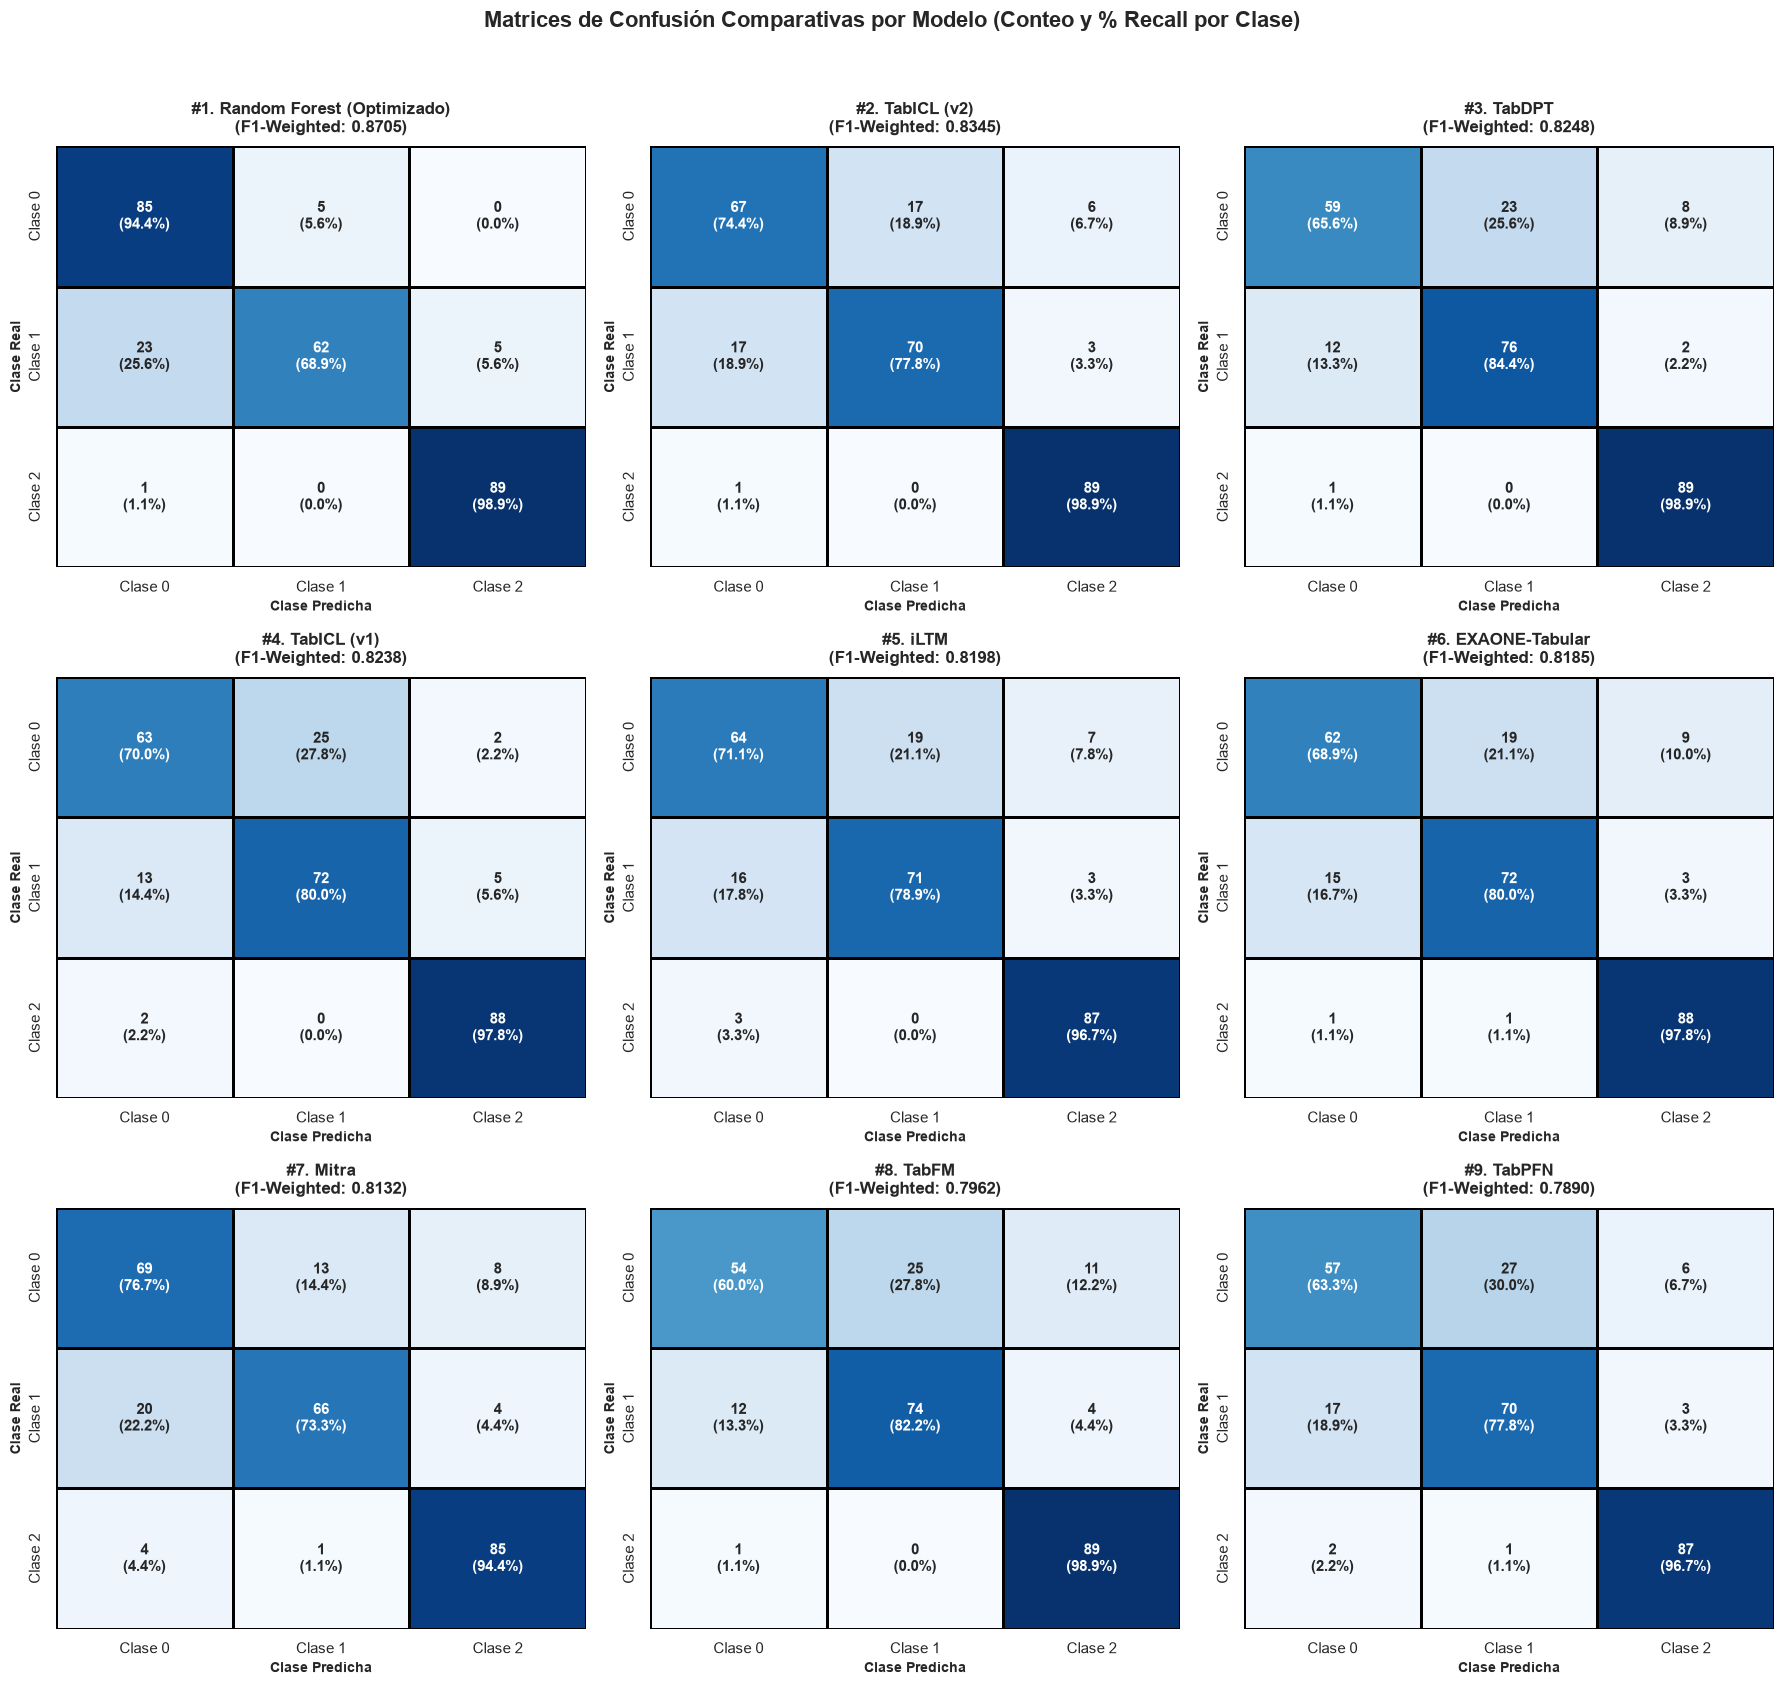

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score

# 1. Catálogo de los 9 modelos (mismas variables que en 6.1.1)
CATALOGO_COMPLETO = [
    ("Random Forest (Optimizado)", "Ensamble tradicional",           "y_pred_rf_opt",   "y_prob_rf_opt"),
    ("iLTM",                       "TFM - Integrado (árboles+MLP)",  "y_pred_iltm",     "y_prob_iltm"),
    ("TabDPT",                     "TFM - Datos reales",             "y_pred_tabdpt",   "y_prob_tabdpt"),
    ("TabICL (v2)",                "TFM - Prior sintético mejorado", "y_pred_tabiclv2", "y_prob_tabiclv2"),
    ("TabICL (v1)",                "TFM - Prior sintético",          "y_pred_tabicl",   "y_prob_tabicl"),
    ("EXAONE-Tabular",             "TFM - CAST",                     "y_pred_exaone",   "y_prob_exaone"),
    ("TabFM",                      "TFM - Foundation Model",         "y_pred_tabfm",    "y_prob_tabfm"),
    ("Mitra",                      "TFM - Prior mixto",              "y_pred_mitra",    "y_prob_mitra"),
    ("TabPFN",                     "TFM - Prior sintético",          "y_pred_tabpfn",   "y_prob_tabpfn"),
]

g = globals()
y_true = np.asarray(y_res).ravel()
clases = sorted(np.unique(y_true))
etiquetas_clases = [f"Clase {c}" for c in clases]

# 2. Recuperar predicciones válidas y ordenarlas de mejor a menor F1-Score
modelos_cargados = []
for nombre, familia, v_pred, v_prob in CATALOGO_COMPLETO:
    p_encontrado = None
    for vp_cand in [v_pred, v_pred.replace("_", ""), v_pred.replace("v2", "2")]:
        if vp_cand in g:
            p_encontrado = g[vp_cand]
            break
    if p_encontrado is not None:
        yp = np.asarray(p_encontrado).ravel()
        if len(yp) == len(y_true):
            f1_val = f1_score(y_true, yp, average="weighted", zero_division=0)
            modelos_cargados.append((nombre, familia, yp, f1_val))

modelos_cargados.sort(key=lambda x: x[3], reverse=True)

# 3. Construir y mostrar la Tabla Consolidada de Matrices de Confusión en el Notebook
filas_tablas_cm = []
diccionario_tablas_cm = {}

for rank, (nombre, familia, yp, f1_val) in enumerate(modelos_cargados, start=1):
    cm = confusion_matrix(y_true, yp, labels=clases)
    cm_pct = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100.0
    
    # Guardar DataFrame individual por si deseas consultarlo por separado
    df_cm_ind = pd.DataFrame(
        cm,
        index=[f"Real: Clase {c}" for c in clases],
        columns=[f"Pred: Clase {c}" for c in clases]
    )
    df_cm_ind["Total Real"] = cm.sum(axis=1)
    df_cm_ind["Acierto / Recall (%)"] = np.diag(cm_pct).round(2)
    diccionario_tablas_cm[nombre] = df_cm_ind

    for i, c_real in enumerate(clases):
        fila = {
            "Ranking": rank,
            "Modelo": nombre,
            "Clase Real": f"Clase {c_real}",
        }
        for j, c_pred in enumerate(clases):
            fila[f"Pred: Clase {c_pred}"] = int(cm[i, j])
        fila["Total Real"] = int(cm[i].sum())
        fila["Recall Clase (%)"] = round(float(cm_pct[i, i]), 2)
        filas_tablas_cm.append(fila)

df_todas_cm = pd.DataFrame(filas_tablas_cm)
print(f"=== TABLA CONSOLIDADA DE MATRICES DE CONFUSIÓN ({len(modelos_cargados)} MODELOS) ===")
display(df_todas_cm)

# 4. Graficar el Panel 3x3 con las Matrices de Confusión de todos los modelos
n_mods = len(modelos_cargados)
ncols = 3
nrows = int(np.ceil(n_mods / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5.5 * nrows))
axes = np.array(axes).reshape(-1)

for idx, (nombre, familia, yp, f1_val) in enumerate(modelos_cargados):
    ax = axes[idx]
    cm = confusion_matrix(y_true, yp, labels=clases)
    cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    
    # Etiqueta combinada: Conteo exacto + Porcentaje por fila (Sensibilidad)
    anotaciones = np.empty(cm.shape, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            anotaciones[i, j] = f"{cm[i, j]}\n({cm_norm[i, j]*100:.1f}%)"
            
    sns.heatmap(
        cm_norm, annot=anotaciones, fmt="", cmap="Blues", cbar=False,
        xticklabels=etiquetas_clases, yticklabels=etiquetas_clases,
        linewidths=1, linecolor="black", ax=ax,
        annot_kws={"size": 11, "weight": "bold"}, vmin=0, vmax=1
    )
    ax.set_title(f"#{idx+1}. {nombre}\n(F1-Weighted: {f1_val:.4f})", fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Clase Predicha", fontsize=10, fontweight="bold")
    ax.set_ylabel("Clase Real", fontsize=10, fontweight="bold")

# Ocultar ejes sobrantes si hubiera menos de 9 modelos activos
for idx in range(n_mods, len(axes)):
    axes[idx].axis("off")

plt.suptitle("Matrices de Confusión Comparativas por Modelo (Conteo y % Recall por Clase)",
             fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../docs/Matrices_Confusion_9_Modelos.png", dpi=300, bbox_inches="tight")
plt.show()

### 6.2 Exportación de resultados <a id="s6-2"></a>

In [49]:
import sys
import subprocess
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, cohen_kappa_score, matthews_corrcoef, confusion_matrix
)
from sklearn.preprocessing import label_binarize

# Asegurar que openpyxl esté disponible para el formateo del Excel
try:
    import openpyxl
    from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
    from openpyxl.utils import get_column_letter
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "openpyxl", "-q"])
    import openpyxl
    from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
    from openpyxl.utils import get_column_letter

# 1. Catálogo completo de los 9 modelos de la tesis
CATALOGO_COMPLETO = [
    ("Random Forest (Optimizado)", "Ensamble tradicional",           "y_pred_rf_opt",   "y_prob_rf_opt"),
    ("iLTM",                       "TFM - Integrado (árboles+MLP)",  "y_pred_iltm",     "y_prob_iltm"),
    ("TabDPT",                     "TFM - Datos reales",             "y_pred_tabdpt",   "y_prob_tabdpt"),
    ("TabICL (v2)",                "TFM - Prior sintético mejorado", "y_pred_tabiclv2", "y_prob_tabiclv2"),
    ("TabICL (v1)",                "TFM - Prior sintético",          "y_pred_tabicl",   "y_prob_tabicl"),
    ("EXAONE-Tabular",             "TFM - CAST",                     "y_pred_exaone",   "y_prob_exaone"),
    ("TabFM",                      "TFM - Foundation Model",         "y_pred_tabfm",    "y_prob_tabfm"),
    ("Mitra",                      "TFM - Prior mixto",              "y_pred_mitra",    "y_prob_mitra"),
    ("TabPFN",                     "TFM - Prior sintético",          "y_pred_tabpfn",   "y_prob_tabpfn"),
]

g = globals()
y_true = np.asarray(y_res).ravel()
clases = sorted(np.unique(y_true))
y_true_bin = label_binarize(y_true, classes=clases)

# 2. Recolectar datos y calcular métricas globales
datos_globales = []
preds_guardadas = {}
probs_guardadas = {}

for nombre, familia, v_pred, v_prob in CATALOGO_COMPLETO:
    p_enc, pr_enc = None, None
    for vp_cand in [v_pred, v_pred.replace("_", ""), v_pred.replace("v2", "2")]:
        if vp_cand in g:
            p_enc = g[vp_cand]
            break
    for vpr_cand in [v_prob, v_prob.replace("_", ""), v_prob.replace("v2", "2")]:
        if vpr_cand in g:
            pr_enc = g[vpr_cand]
            break

    if p_enc is None or pr_enc is None:
        continue

    yp = np.asarray(p_enc).ravel()
    pr = np.asarray(pr_enc)
    if len(yp) != len(y_true) or len(pr) != len(y_true):
        continue

    preds_guardadas[nombre] = yp
    probs_guardadas[nombre] = pr

    datos_globales.append({
        "Modelo": nombre,
        "Familia_Enfoque": familia,
        "Accuracy": accuracy_score(y_true, yp),
        "Precision (Weighted)": precision_score(y_true, yp, average="weighted", zero_division=0),
        "Recall (Weighted)": recall_score(y_true, yp, average="weighted", zero_division=0),
        "F1-Score (Weighted)": f1_score(y_true, yp, average="weighted", zero_division=0),
        "F1-Score (Macro)": f1_score(y_true, yp, average="macro", zero_division=0),
        "ROC-AUC (OvR)": roc_auc_score(y_true_bin, pr, average="weighted", multi_class="ovr"),
        "Cohen_Kappa": cohen_kappa_score(y_true, yp),
        "MCC": matthews_corrcoef(y_true, yp),
    })

# Ordenar por F1-Score (Weighted) y ROC-AUC
df_global = (pd.DataFrame(datos_globales)
             .sort_values(["F1-Score (Weighted)", "ROC-AUC (OvR)"], ascending=False)
             .reset_index(drop=True))
df_global.insert(0, "Ranking", np.arange(1, len(df_global) + 1))

max_f1 = df_global["F1-Score (Weighted)"].max()
max_auc = df_global["ROC-AUC (OvR)"].max()
df_global["Brecha_vs_Top1_F1"] = df_global["F1-Score (Weighted)"] - max_f1
df_global["Brecha_vs_Top1_AUC"] = df_global["ROC-AUC (OvR)"] - max_auc

# 3. Construir Hoja 2: Métricas desglosadas por Clase
filas_clase = []
for _, row in df_global.iterrows():
    nombre = row["Modelo"]
    yp = preds_guardadas[nombre]
    pr = probs_guardadas[nombre]
    
    p_c = precision_score(y_true, yp, labels=clases, average=None, zero_division=0)
    r_c = recall_score(y_true, yp, labels=clases, average=None, zero_division=0)
    f1_c = f1_score(y_true, yp, labels=clases, average=None, zero_division=0)
    
    for idx_c, c_val in enumerate(clases):
        auc_c = roc_auc_score(y_true_bin[:, idx_c], pr[:, idx_c])
        soporte = int(np.sum(y_true == c_val))
        filas_clase.append({
            "Ranking": row["Ranking"],
            "Modelo": nombre,
            "Familia_Enfoque": row["Familia_Enfoque"],
            "Clase": f"Clase {c_val}",
            "Precision": p_c[idx_c],
            "Recall (Sensibilidad)": r_c[idx_c],
            "F1-Score": f1_c[idx_c],
            "ROC-AUC (Clase OvR)": auc_c,
            "Soporte (Muestras)": soporte
        })

df_por_clase = pd.DataFrame(filas_clase)

# 4. Construir Hoja 3: Matrices de Confusión (Conteo y Porcentaje)
filas_cm_excel = []
for _, row in df_global.iterrows():
    nombre = row["Modelo"]
    yp = preds_guardadas[nombre]
    cm = confusion_matrix(y_true, yp, labels=clases)
    cm_pct = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100.0
    
    for i, c_real in enumerate(clases):
        reg = {
            "Ranking": row["Ranking"],
            "Modelo": nombre,
            "Clase Real": f"Real: Clase {c_real}"
        }
        for j, c_pred in enumerate(clases):
            reg[f"Pred: Clase {c_pred} (N)"] = int(cm[i, j])
        for j, c_pred in enumerate(clases):
            reg[f"Pred: Clase {c_pred} (%)"] = round(float(cm_pct[i, j]), 2)
        reg["Total Muestras Reales"] = int(cm[i].sum())
        reg["Sensibilidad / Recall (%)"] = round(float(cm_pct[i, i]), 2)
        filas_cm_excel.append(reg)

df_cm_excel = pd.DataFrame(filas_cm_excel)

# 5. Construir Hoja 4: Desempeño por Fold (5 Folds de StratifiedGroupKFold)
filas_folds = []
if "cv_sgkf" in g and "X_selected" in g and "groups_res" in g:
    X_ref = np.asarray(X_selected)
    grupos_ref = np.asarray(groups_res)
    
    for _, row in df_global.iterrows():
        nombre = row["Modelo"]
        yp = preds_guardadas[nombre]
        pr = probs_guardadas[nombre]
        
        acc_list, f1_list, auc_list = [], [], []
        for fold_idx, (_, test_idx) in enumerate(cv_sgkf.split(X_ref, y_true, groups=grupos_ref), start=1):
            acc_f = accuracy_score(y_true[test_idx], yp[test_idx])
            f1_f = f1_score(y_true[test_idx], yp[test_idx], average="weighted", zero_division=0)
            try:
                auc_f = roc_auc_score(y_true_bin[test_idx], pr[test_idx], average="weighted", multi_class="ovr")
            except Exception:
                auc_f = np.nan
                
            acc_list.append(acc_f)
            f1_list.append(f1_f)
            auc_list.append(auc_f)
            
            filas_folds.append({
                "Ranking": row["Ranking"],
                "Modelo": nombre,
                "Particion_CV": f"Fold {fold_idx}",
                "N_Muestras_Fold": len(test_idx),
                "Accuracy": acc_f,
                "F1-Score (Weighted)": f1_f,
                "ROC-AUC (OvR)": auc_f
            })
            
        # Agregar Media y Desviación Estándar de los 5 Folds
        filas_folds.append({
            "Ranking": row["Ranking"],
            "Modelo": nombre,
            "Particion_CV": "MEDIA (5 Folds)",
            "N_Muestras_Fold": len(y_true),
            "Accuracy": float(np.mean(acc_list)),
            "F1-Score (Weighted)": float(np.mean(f1_list)),
            "ROC-AUC (OvR)": float(np.nanmean(auc_list))
        })
        filas_folds.append({
            "Ranking": row["Ranking"],
            "Modelo": nombre,
            "Particion_CV": "DESV. ESTÁNDAR",
            "N_Muestras_Fold": 0,
            "Accuracy": float(np.std(acc_list, ddof=1)),
            "F1-Score (Weighted)": float(np.std(f1_list, ddof=1)),
            "ROC-AUC (OvR)": float(np.nanstd(auc_list, ddof=1))
        })

df_folds_excel = pd.DataFrame(filas_folds)

# 6. Construir Hoja 5: Predicciones Out-Of-Fold (OOF) completas muestra por muestra
df_oof = pd.DataFrame({
    "ID_Ventana": np.arange(len(y_true)),
    "Sujeto_Grupo": np.asarray(groups_res) if "groups_res" in g else np.nan,
    "Clase_Real": y_true
})
for _, row in df_global.iterrows():
    nombre = row["Modelo"]
    yp = preds_guardadas[nombre]
    df_oof[f"Pred_{nombre}"] = yp
    df_oof[f"Acierto_{nombre}"] = (yp == y_true).astype(int)

# 7. Guardar y aplicar estilo ejecutivo en Excel
ruta_excel = "../docs/Resultados_Comparativa_9_Modelos_Tesis.xlsx"

with pd.ExcelWriter(ruta_excel, engine="openpyxl") as writer:
    df_global.round(4).to_excel(writer, sheet_name="Ranking_Global", index=False)
    df_por_clase.round(4).to_excel(writer, sheet_name="Metricas_Por_Clase", index=False)
    df_cm_excel.to_excel(writer, sheet_name="Matrices_de_Confusion", index=False)
    if not df_folds_excel.empty:
        df_folds_excel.round(4).to_excel(writer, sheet_name="Rendimiento_Por_Fold_CV", index=False)
    df_oof.to_excel(writer, sheet_name="Predicciones_OOF", index=False)

    # Formateo visual de encabezados, bordes y ancho automático
    fill_header = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
    font_header = Font(color="FFFFFF", bold=True, size=11)
    border_thin = Border(
        left=Side(style="thin", color="D9D9D9"),
        right=Side(style="thin", color="D9D9D9"),
        top=Side(style="thin", color="D9D9D9"),
        bottom=Side(style="thin", color="D9D9D9")
    )

    for sheet_name, ws in writer.sheets.items():
        ws.views.sheetView[0].showGridLines = True
        ws.freeze_panes = "A2"
        
        for cell in ws[1]:
            cell.fill = fill_header
            cell.font = font_header
            cell.alignment = Alignment(horizontal="center", vertical="center")
            
        for row in ws.iter_rows(min_row=2, max_row=ws.max_row, min_col=1, max_col=ws.max_column):
            for cell in row:
                cell.border = border_thin
                if isinstance(cell.value, float):
                    cell.number_format = "0.0000"
                    
        for col in ws.columns:
            max_len = max(len(str(cell.value or "")) for cell in col)
            col_letter = get_column_letter(col[0].column)
            ws.column_dimensions[col_letter].width = min(max(max_len + 4, 13), 36)

print(f"✅ Archivo Excel exportado exitosamente: {ruta_excel}")
print(f"📊 Pestañas generadas: {list(openpyxl.load_workbook(ruta_excel).sheetnames)}")

✅ Archivo Excel exportado exitosamente: ../docs/Resultados_Comparativa_9_Modelos_Tesis.xlsx
📊 Pestañas generadas: ['Ranking_Global', 'Metricas_Por_Clase', 'Matrices_de_Confusion', 'Rendimiento_Por_Fold_CV', 'Predicciones_OOF']


### 6.3 Interpretación de resultados <a id="s6-3"></a>

Métricas calculadas con `StratifiedGroupKFold(5)` sobre 270 muestras balanceadas (90 por clase) y 18 variables, sin ruido. F1-Score y AUC-ROC son ponderados (AUC One-vs-Rest). Clases: 0 = reposo, 1 = emoción positiva, 2 = estrés.

**Random Forest (Optimizado):** obtiene el mejor desempeño en exactitud y F1 bajo StratifiedGroupKFold, con Accuracy de 0.874, F1-Score ponderado de 0.870 y AUC-ROC de 0.953. Su punto débil es la clase 1, con un recall de 0.69 (confunde 23 de 90 casos con la clase 0), frente a 0.94 en la clase 0 y 0.99 en la clase 2.

**TabICL (v1):** obtiene Accuracy de 0.826, F1-Score de 0.824 y AUC-ROC de 0.946, quedando 1.1 puntos de Accuracy por debajo de su versión v2, con un recall de 0.70 en la clase 0, 0.80 en la clase 1 y 0.98 en la clase 2.

**TabICL (v2):** lidera entre los modelos fundacionales por Accuracy y F1-Score sin ajuste de hiperparámetros (zero-shot), con Accuracy de 0.837, F1-Score de 0.835 y AUC-ROC de 0.949. Presenta un recall equilibrado entre las clases 0 y 1 (0.74 y 0.78) y mantiene 0.99 en la clase 2.

**Mitra:** registra Accuracy de 0.807, F1-Score de 0.806 y AUC-ROC de 0.930, ubicándose en el bloque inferior junto con TabFM y TabPFN. Es el único modelo fundacional cuyo menor recall no está en la clase 0 sino en la clase 1 (0.72, frente a 0.77 en la clase 0 y 0.93 en la clase 2). Su tiempo de inferencia fue de ≈10 s en la ejecución realizada.

**TabDPT:** alcanza Accuracy de 0.830, F1-Score de 0.825 y AUC-ROC de 0.952, prácticamente igual al del Random Forest en AUC-ROC (diferencia de 0.001). Logra el mayor recall en la clase 1 de todo el estudio (0.84), aunque su recall cae en la clase 0 (0.66).

**iLTM:** registra Accuracy de 0.822 y F1-Score de 0.820, pero alcanza el mayor AUC-ROC de los nueve modelos evaluados (0.955), superando ligeramente al Random Forest en discriminación probabilística. Muestra recalls de 0.71, 0.79 y 0.97 en las clases 0, 1 y 2. Fue el modelo más lento (≈63 s).

**EXAONE-Tabular:** empata en exactitud con iLTM (Accuracy de 0.822 y F1-Score de 0.819) y logra un AUC-ROC de 0.943, destacando por una buena sensibilidad en las clases 1 (0.80) y 2 (0.98) frente a 0.69 en la clase 0.

**TabFM:** alcanza Accuracy de 0.804, F1-Score de 0.796 y AUC-ROC de 0.939. Presenta el recall más bajo en la clase 0 de todo el estudio (0.60), compensado por un alto desempeño en las clases 1 (0.82) y 2 (0.99). Su tiempo de inferencia fue de ≈46 s.

**TabPFN:** registra los valores más bajos en clasificación directa (Accuracy de 0.793 y F1-Score de 0.789), aunque mantiene un AUC-ROC competitivo de 0.933, viendo afectado su rendimiento global por la confusión de la clase 0 (recall de 0.63) hacia la clase 1.

**Síntesis comparativa:** en datos limpios, el Random Forest optimizado supera a los ocho modelos fundacionales por entre 3.7 y 8.2 puntos porcentuales de Accuracy (y entre 3.6 y 8.2 puntos de F1-Score). Sin embargo, mientras el Random Forest concentra su ventaja en la clase 0 (recall de 0.94 vs. 0.60–0.77 en los TFM), todos los modelos fundacionales lo superan en la detección de la clase 1 (recalls de 0.72 a 0.84 frente a 0.69 del RF). La clase 2 (estrés) es la mejor reconocida por todos los modelos (recall de 0.93 a 0.99): la confusión se concentra entre el reposo y la emoción positiva. En el bloque superior de modelos fundacionales (TabICL v2, TabDPT, TabICL v1, iLTM y EXAONE-Tabular), las diferencias de Accuracy son de a lo sumo 1.5 puntos porcentuales (equivalentes a entre 1 y 4 observaciones de las 270 evaluadas) y sus AUC-ROC superan el 0.943 —con iLTM liderando en 0.955—, lo que exige una prueba estadística por pliegues para establecer diferencias significativas. Mitra, TabFM y TabPFN conforman el bloque inferior en exactitud (0.793–0.807). En cuanto a tiempos de inferencia (5 folds, RTX 5060), van desde ≈4 s (TabICL v2 y TabPFN) hasta ≈63 s (iLTM). Estos resultados corresponden a datos sin ruido (In-Distribution): la degradación ante ruido sintético se evalúa en este cuaderno únicamente para el Random Forest (sección 5.1).

## 7. Deployment <a id="s7"></a>

### 7.1 Artefactos generados <a id="s7-1"></a>

- `Resultados_Comparativa_9_Modelos_Tesis.xlsx`: hojas `Ranking_Global`, `Metricas_Por_Clase`, `Matrices_de_Confusion`, `Rendimiento_Por_Fold_CV` y `Predicciones_OOF`.
- `Grafico_Barras_9_Modelos.png`: comparativa de Accuracy, F1-Score y ROC-AUC por modelo.
- `Matrices_Confusion_9_Modelos.png`: matrices de confusión de los nueve modelos.

### 7.2 Conclusiones <a id="s7-2"></a>

- **Robustez al ruido:** el Random Forest pasa de F1 = 0.969 y AUC = 0.998 sin ruido a F1 = 0.448 y AUC = 0.521 con SNR = 0.01 (sección 5.1).
- **Comparación de modelos (18 variables, validación por sujeto):** el Random Forest optimizado logra la mayor Accuracy y F1 (0.874 y 0.870); iLTM logra el mayor AUC-ROC (0.955, frente a 0.953 del Random Forest).
- **Modelos fundacionales:** sin ajuste de hiperparámetros, TabICL v2 es el mejor en Accuracy y F1 (0.837 y 0.835); los cinco primeros quedan a menos de 1.5 puntos de Accuracy entre sí.
- **Por clase:** el estrés (clase 2) es la clase mejor reconocida por todos los modelos; los errores se concentran entre el reposo (clase 0) y la emoción positiva (clase 1).